# Single-stage KG-GT notebook (Using `main` module)

This notebook is a copy of `main.ipynb` that trains **one stage**: the full KG-GT model
(Transformer encoder → muscle-node projection → kinematics-guided GAT → per-muscle decoder,
plus the kinematic skip highway and lag alignment) is trained **jointly from scratch**, with
every parameter trainable from the first epoch.

**What is different from `main.ipynb`**

| | `main.ipynb` (two-stage) | `main_1stage.ipynb` (this notebook) |
|---|---|---|
| Stage 1 | Transformer-only EEG model, `stage1_lr`=1e-3, 75 epochs | — (none) |
| Stage 2 / training | KG-GT, encoder/node-proj loaded from stage 1, everything except GAT, decoder, kin-skip, node-proj and the last 1–2 encoder layers **frozen**, `stage2_lr`=1e-4, `reduce` scheduler, no warmup, early stop after 25 epochs | KG-GT, **nothing frozen**, `single_stage.lr`=1e-3, `cosine` + 5 warmup epochs (AdamW), `single_stage.epochs`=200 |
| GAT / decoder init | re-initialised between stages | trained together with the encoder from epoch 1 |
| Checkpoints | `outputs/checkpoints_main_stage1/…`, `outputs/checkpoints_main_stage2/…` | `outputs/checkpoints_1stage/{subject}/` (`last.pt` + `best.pt`, resumable) |
| Results | `results/evaluation_report.md`, `results/magnitude_report.*`, `results/magnitude_by_load.*`, `outputs/interpretability/`, `outputs/losocv_results.csv` | `results/evaluation_report_1stage.md`, `results/magnitude_report_1stage.*`, `results/magnitude_by_load_1stage.*`, `outputs/interpretability_1stage/`, `outputs/losocv_results_1stage.csv`, `results/input_ablation_1stage.*` |

Everything else is identical to `main.ipynb`: same participants and condition-stratified
train/val/test split, same preprocessing and **same cache** (`data/cache_main_stride500_square_pose_force_sg51`;
preprocessing is identical, only training differs), same 24 kinematic inputs (10 hand-pose + 2
hand-near-object gated forces F_L, F_G → GAT edge bias; the gated forces + 10 SG-51 pose velocities +
2 gated-force velocities → additive kin skip highway), same loss (asymmetry 1.5, rest over-prediction
term, Huber δ=2.5, active-level term w_height 0.5, per-muscle weights), batch size,
gradient accumulation, grad clipping, AMP and seed. The parameter groups used by `train_model`
are the same as in stage 1 of `main.ipynb` (`transformer_lr_scale`=0.1 → encoder + node projection at
1e-4, GAT/decoder at 1e-3, kin-skip at lr/3 with stronger weight decay).

After the evaluation come the magnitude evaluation (burst height / rest level per test series and
hold-phase level per weight / surface, as in `main.ipynb`) and a new cell: **"How much does the model use EEG vs kinematics?"**
— Pearson r on the test set with the kinematics zeroed / time-shuffled and with the EEG time-shuffled.

**How to compare with `main.ipynb`:** run both notebooks on the same `subject_list`; compare
`results/evaluation_report.md` (two-stage) with `results/evaluation_report_1stage.md` (this one) —
same test series, same metrics — and the best epoch / final val loss printed by the training loops.
The input-ablation cell can also be pasted into `main.ipynb` to see whether the two training schemes
rely on EEG and kinematics differently.


In [1]:
import torch
import numpy as np
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import copy
from pathlib import Path

# Import from main
from main import (
    get_device, set_seed,
    load_participant, get_split_series,
    series_conditions, stratified_split, describe_split,
    preprocess_eeg, preprocess_eeg_from_config,
    preprocess_emg, preprocess_emg_from_config, EMGNormalizer,
    preprocess_kinematics, preprocess_kinematics_from_config, KinNormalizer,
    extract_kt, extract_kt_raw,
    WAYEEGDataset,
    KGGTModel, build_kg_gt_from_config, CNN1dAligner,
    build_transformer_only_from_config,
    CombinedEMGLoss, CompositeEMGLoss, CCCLoss, PearsonCorrelationLoss, TemporalSmoothnessLoss,
    build_loss_from_config,
    train_model, TrainConfig, TrainResult,
    collect_predictions, compute_metrics, EvalMetrics,
    prepare_batch_factory, save_checkpoint, load_checkpoint,
    print_gpu_info,
    compute_muscle_edge_prior,   # for edge-prior computation (follow-up step)
)

ROOT = Path(".")

In [2]:
set_seed(42)
device = get_device()
torch.backends.cudnn.benchmark = True
print(f"Device: {device}")


Device: cuda


In [10]:
CONFIG = {
    # ── Step 1: magnitude (on top of Package 1) ─────────────────────────────────
    # * gated load / grip force also feed the additive kin skip highway (amplitude path),
    #   not only the GAT edge bias; the velocities of the gated forces are kept as
    #   force-rate inputs → 24 kin features (same 26-column cache, other drop_indices)
    # * loss: asymmetry 1.5, huber_delta 2.5, new active-level term w_height 0.5
    # * stage 2: lr 1e-4 + early stop after 25 epochs without val improvement
    # move aside outputs/checkpoints_1stage (this notebook; main.ipynb uses its own two-stage folders)
    # before the first run (model input is now 24 features; resume=True would
    # otherwise try to load checkpoints of the old shape).
    "outputs":{
        "figures_dir": "docs/figure/method1",
        "run_tag": "step1",   # appended to the results/P{id}/main/<config> plot folder → no overwrite of older runs
    },
    "data": {
        "participant": "P1",       
        "data_root": "data/way-eeg/raw",
        "cache_dir": "data/cache_main_stride500_square_pose_force_sg51",  # new folder: hand pose + hand-near-object gated forces (26 cached kin cols)
        # window_size=4000 @ 500 Hz = 8 s window; stride=250 = 0.5 s step
        # chunked transformer: 4000 / chunk_size=500 = 8 chunks of 500 → O(500²) not O(4000²)
        "window_size": 500,
        "stride": 500,
        # latency_shift_ms eliminated: Transformer attention learns asymmetric corticomuscular conduction delay
        "fs_eeg": 500,                   # Hz
        "fs_emg": 4000,                  # Hz (raw); downsampled to fs_eeg after preprocess
        "fs_kin": 500,                   # Hz
        "n_eeg_channels": 32,
        "n_emg_channels": 5,
        "n_kin_raw": 36,                 # raw kin cols in hs.kin.sig
        "n_kin_features": 24             # model input: hand pose (10) + gated F_L, F_G (2) + pose velocity (10) + gated F_L, F_G velocity (2)
    },
    "preprocessing": {
        "eeg": {
            "bp_low": 0.5,                  # Hz, bandpass lower bound
            "bp_high": 40.0,                # Hz, bandpass upper bound
            "artifact_method": "ica_auto",  # "asr" | "ica_auto" | "ica_manual"
            "filter_order": 4,
            "notch_freq": 50.0,             # Hz, power-line
            "asr_window_ms": 500,           # ms, ASR sliding window
            "asr_std_thresh": 5.0,          # sigma, ASR rejection threshold
            "delta_low": 0.5,               # Hz, delta-band lower bound
            "delta_high": 40.0,             # Hz, delta-band upper bound
            "use_car": False,
            "use_tkeo": True,
            #"target_channels": ["FC1", "FC2", "C3", "Cz", "C4", "CP1", "CP2", "CP6"]
        },
        "emg": {
            "bp_low": 30.0,              # Hz
            "bp_high": 300.0,            # Hz
            "filter_order": 4,
            "lp_cutoff": 8.0,            # Hz, near-DC → flat-top square-like activation bursts
            "lp_order": 4,               # 8th-order → brick-wall roll-off, flat plateau between bursts
            "downsample_factor": 8,      # 4000 -> 500 Hz
            "envelope_method": "tkeo", # strictly causal full-wave rectification default
            "causal": True,              # strict forward-only causal filtering (no lookahead)
        },
        "kinematics": {
            "include_velocity": True,      # if true, output includes velocity
            "include_acceleration": False, # off: the SG 2nd derivative amplifies marker jitter at rest
            # Object forces count only while the hand is at the object: F_L, F_G are multiplied by a gate
            # (1 while index-object distance <= near_cm, linear ramp to 0 at far_cm, 0.1 s zero-phase
            # smoothing) BEFORE velocities are computed. Loading of the object by someone else while the
            # hand is parked (~28 cm away) is removed. None / absent = forces not gated.
            "gated_force": {"near_cm": 12.0, "far_cm": 20.0, "smooth_s": 0.1},
            "drop_indices": [12, 25],  # = POSE_FORCE_RATE_DROP_INDICES: drop rho_GL and its velocity → 24 = [hand pose 10, F_L_gated, F_G_gated, pose velocity 10, v_F_L_gated, v_F_G_gated]
            "velocity_method": "sg",     # 'sg' (Savitzky-Golay) | 'bw' (Butterworth diff)
            "sg_window": 51,             # SG window length (samples, must be odd); 51 = 102 ms at 500 Hz → less jitter at rest
            "sg_poly": 3,                # SG polynomial order
            "bw_cutoff": 20.0,           # LP cutoff Hz before diff (used when method='bw')
            "bw_order": 4,               # Butterworth order (used when method='bw')
            "normalize": True            # per-feature z-score over training set
        },
    },
    "model": {
        "type": "transformer_regressor",
        "transformer": {
            "n_layers": 4,
            "n_heads": 8,
            "d_model": 128,
            "d_k": 32,
            "d_v": 32,
            "ffn_dim": 512,
            "dropout": 0.2,
            # chunk_size=500 with window_size=4000 → 8 chunks of 500
            # → O(500²)=250K scores per head (not O(4000²)=16M)
            # MUST divide window_size evenly or a RuntimeWarning fires and
            # full O(T²) attention is used (catastrophically slow).
            "chunk_size": 500
        },
        "gat": {
            "n_layers": 2,
            "node_dim": 64,
            "hidden_dim": 64,
            "heads": 4,
            "dropout": 0.2,
            "use_kinematic_guidance": True,
            "kin_gat_dim": 12,             # first 12 kin features (pose 10 + gated F_L, F_G) → GAT edge bias
            "kin_skip_indices": list(range(10, 24)),  # → kin skip highway (adds to the node embeddings = amplitude path): gated F_L, F_G + all 12 velocities
        },
        "decoder": {
            "out_channels": 5            # predicted EMG channels
        }
    },
    "training": {
        "loss": {
            "w_peak":          1.0,     # Peak-weighted MSE weight
            "w_ccc":           0.5,     # Concordance Correlation Coefficient weight (prevents Mean Collapse)
            "w_pearson":       0.2,     # Pearson correlation timing weight
            "w_diff":          0.1,     # First-order temporal smoothness weight
            "w_rest":          0.05,    # Resting baseline L1 penalty
            "w_reg":           0.001,   # GAT EdgePrior KL divergence anchor
            "peak_alpha":      3.0,     # Multiplier for burst tips in PeakMSE
            "asymmetry":       1.5,     # Under-prediction penalty (Package 1: 1.2 — too weak a pull towards burst height; 2.0 before)
            "rest_threshold":  0.15,    # Rest threshold fraction
            "eps":             1e-6,    # Denominator clamp for AMP FP16 numerical stability
            "use_peak_weight": True,    # set False for ablation back to standard MSE
            "w_rest_over":     1.0,     # one-sided squared over-prediction where the target is at rest (baseline recovery)
            "huber_delta":     2.5,     # robust peak-weighted error (z units): squared inside ±2.5, linear outside; None = squared (Package 1: 1.0)
            "channel_weights": "auto",  # per-muscle weights ∝ 1/p95(|z|) of the training targets, mean 1 (computed per subject)
            "w_height":        0.5,     # active-level term: per window/muscle, relative error of the mean level above the window minimum over the non-rest samples (under-prediction × asymmetry, smooth-L1)
            "height_eps":      0.5,     # its denominator floor (z units) so noise-only windows do not give huge relative errors
        },
        # ── optimizer ─────────────────────────────────────────────────────
        "optimizer":   "adamw",   # 'adam' | 'adamw'
        "weight_decay": 1e-2,     # AdamW weight decay (ignored for adam)
        # ── scheduler ─────────────────────────────────────────────────────
        "scheduler":   "cosine",  # 'reduce' | 'cosine'
        # reduce-specific
        "lr_patience": 5,
        "lr_factor":   0.5,
        # cosine-specific
        "cosine_t_max":   None,   # None → use max_epochs
        "cosine_eta_min": 1e-6,
        # ── common ────────────────────────────────────────────────────────
        "loss_lambda":  1.0,      # 1.0 = plain MSE; <1.0 enables Soft-DTW (O(T²), DO NOT use at T=4000)
        "stage1_lr": 1e-3,
        "warmup_epochs": 5,
        "stage2_lr": 1e-4,          # two-stage only (unused here)
        "stage2_early_stop_patience": 25,   # two-stage only (unused here)
        "transformer_lr_scale": 0.1,
        # batch_size=4 with T=4000 keeps VRAM safe on GTX 1660 Ti (6 GB).
        # effective batch = batch_size * gradient_accumulation_steps = 4 * 8 = 32
        # Tune batch_size up (e.g. 8) if VRAM is available; reduce grad_accum_steps proportionally.
        "batch_size":          32,
        "gradient_accumulation_steps": 2,
        "early_stop_patience": 25,
        "grad_clip_norm":      1.0,
        "stage1_epochs":       75,  # two-stage only (unused here)
        "max_epochs":          200,
        # use_amp=True: enables FP16 mixed precision via torch.autocast + GradScaler.
        # GTX 1660 Ti (sm_75 Turing) has FP16 tensor cores → ~1.5-2x speedup.
        # Requires PyTorch >= 2.0. Set False only if you see NaN losses.
        "use_amp":             True,
        "log_memory_every":    50,
        "losocv": True,           # leave-one-subject-out cross-validation
        "checkpoint_every":     1,
        # ── single-stage (this notebook) ──────────────────────────────────
        # Checkpoints -> outputs/checkpoints_1stage/{subject}/ — never the two-stage folders.
        "checkpoint_dir": "outputs/checkpoints_1stage",
        # The full KG-GT model is trained ONCE, jointly, nothing frozen.
        # Only lr / epochs live here; everything else is the shared key above:
        #   optimizer="adamw", scheduler="cosine" (eta_min 1e-6), warmup_epochs=5,
        #   transformer_lr_scale=0.1 (encoder+node-proj at lr*0.1, as in stage 1),
        #   early_stop_patience=50, grad_clip_norm, use_amp, batch_size,
        #   gradient_accumulation_steps, seed.
        "single_stage": {
            "lr":     1e-3,     # = stage1_lr (GAT/decoder group; encoder x transformer_lr_scale)
            "epochs": 200,      # = max_epochs
        },
        "seed":                42,
    },
    "dataset": {
        # Keep in sync with data.window_size / data.stride above
        "window_size": 500,
        "stride": 500,
    }
}
# Plot folders (main.plots.get_dynamic_fig_dir) are keyed on training["lr"], which
# otherwise falls back to stage2_lr (= the two-stage folder) — point them at the
# single-stage LR so saved figures do not overwrite main.ipynb's.
CONFIG["training"]["lr"] = CONFIG["training"]["single_stage"]["lr"]
notebook_cfg = copy.deepcopy(CONFIG)

### Train / val / test split (per participant, condition-stratified)

Each participant has 9 series: 5×**W** (weight varies, surface fixed), 2×**S** (surface varies, weight fixed), 2×**B** (both vary), read from `BlockType` in `P{p}_AllLifts.mat`. Series 7, 8, 9 are always W; series 1–6 hold 2 W + 2 S + 2 B in a participant-specific order.

- **test** = the *later* W and the *later* B among series 1–6 → {W, B}
- **val** = series 9 → {W}
- **train** = the earlier W of 1–6, series 7 and 8, both S series, the *earlier* B → {3 W, 2 S, 1 B}

`WAYEEGDataset` applies this automatically (`stratified_split(p)` / `get_split_series(split, p)`); a missing AllLifts file or a composition other than 5W/2S/2B raises an error. The test series ids therefore differ per participant (no longer fixed to 3 and 4). `describe_split(p)` prints the table.

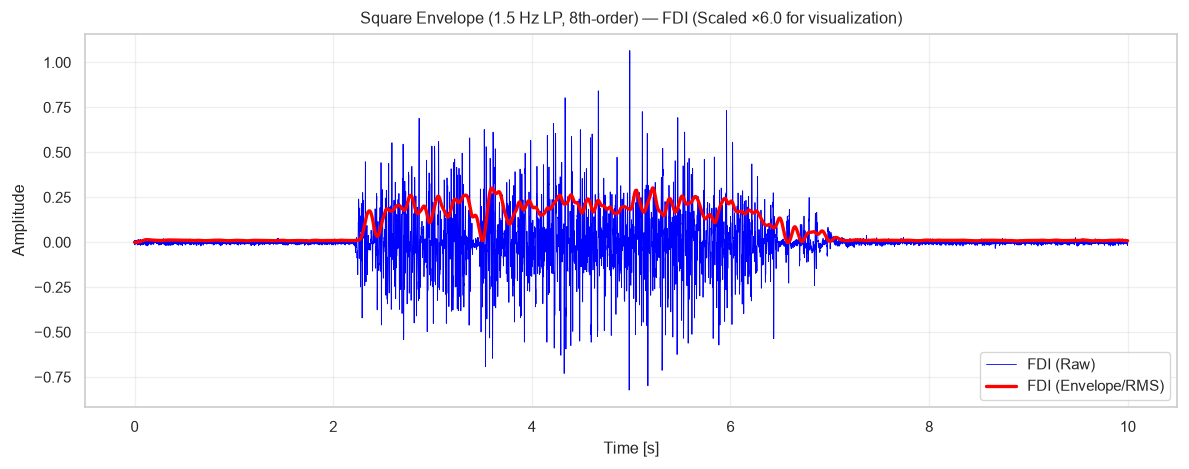

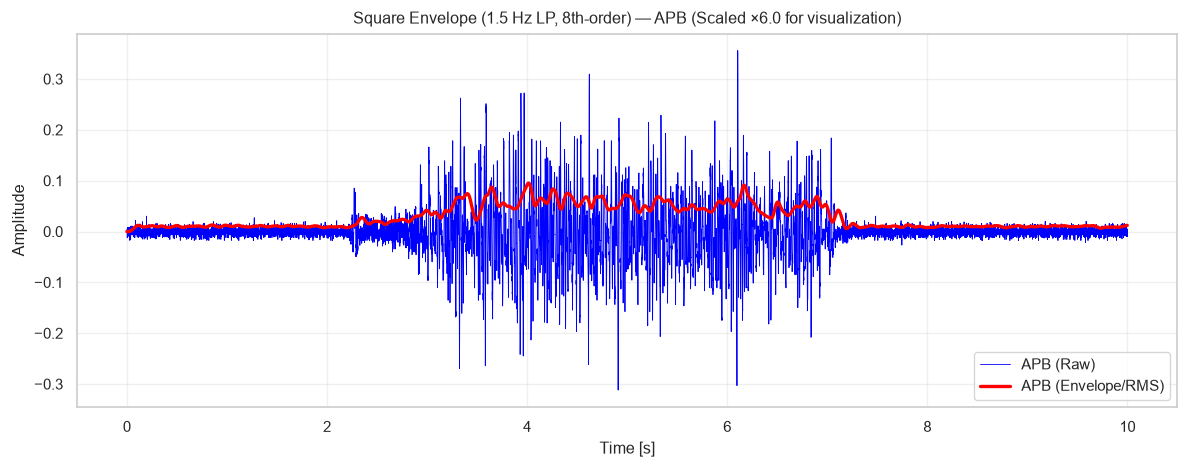

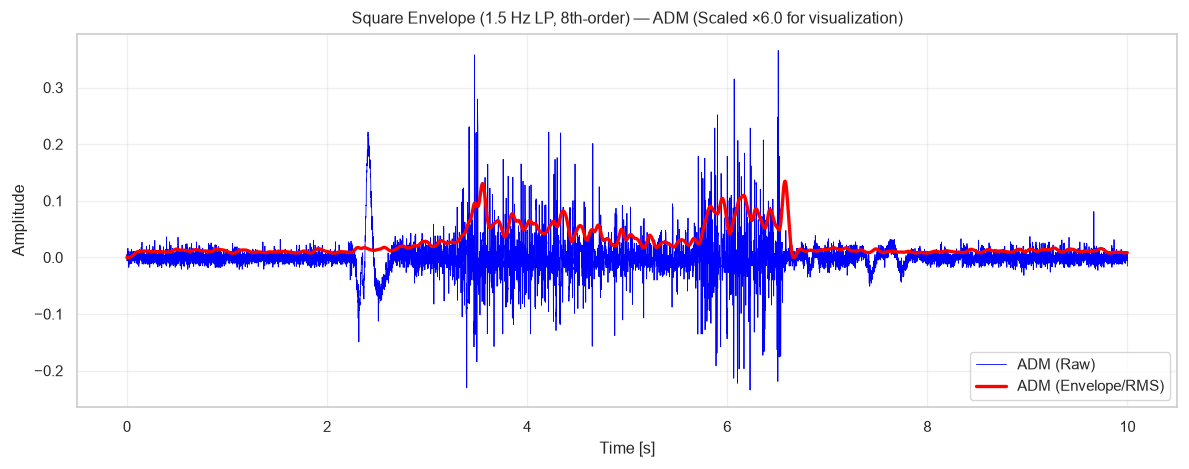

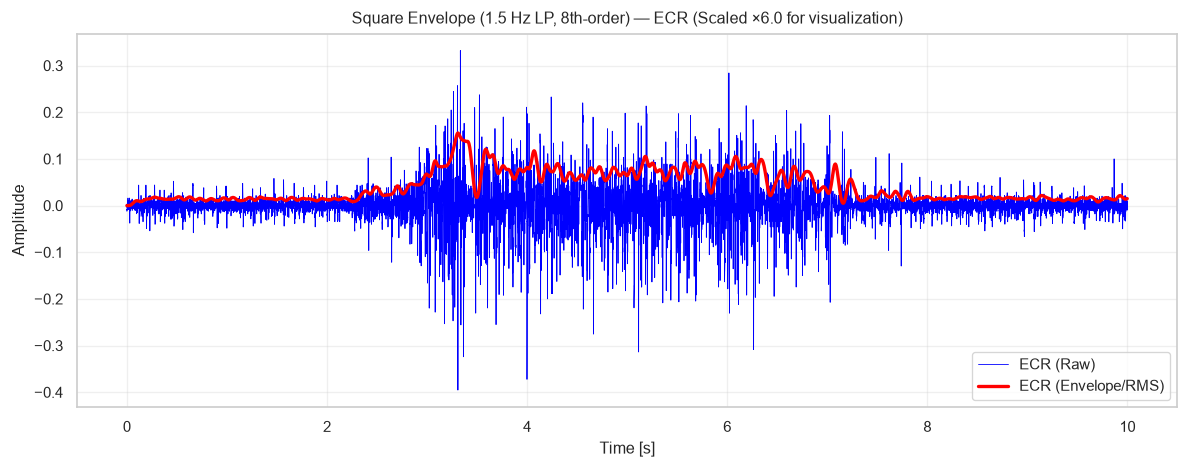

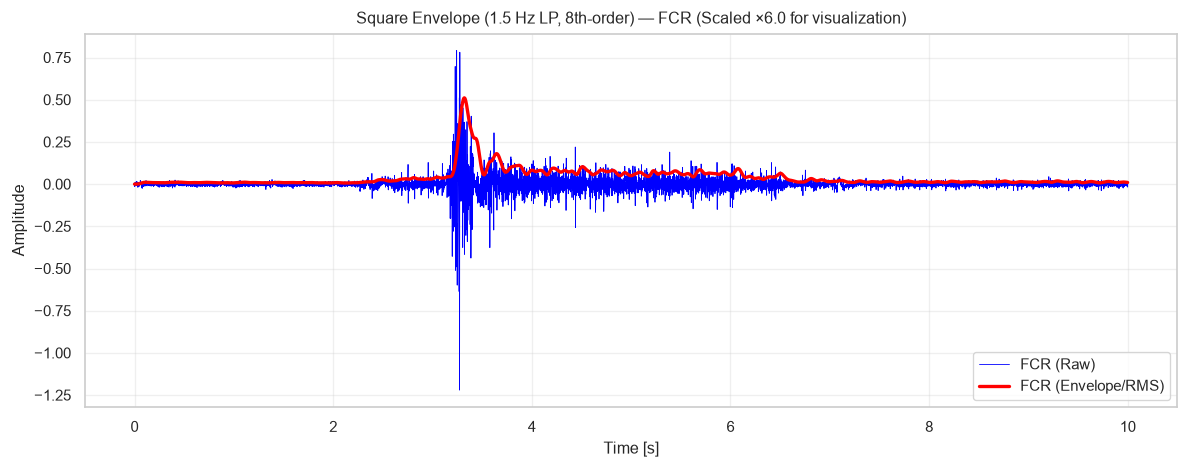

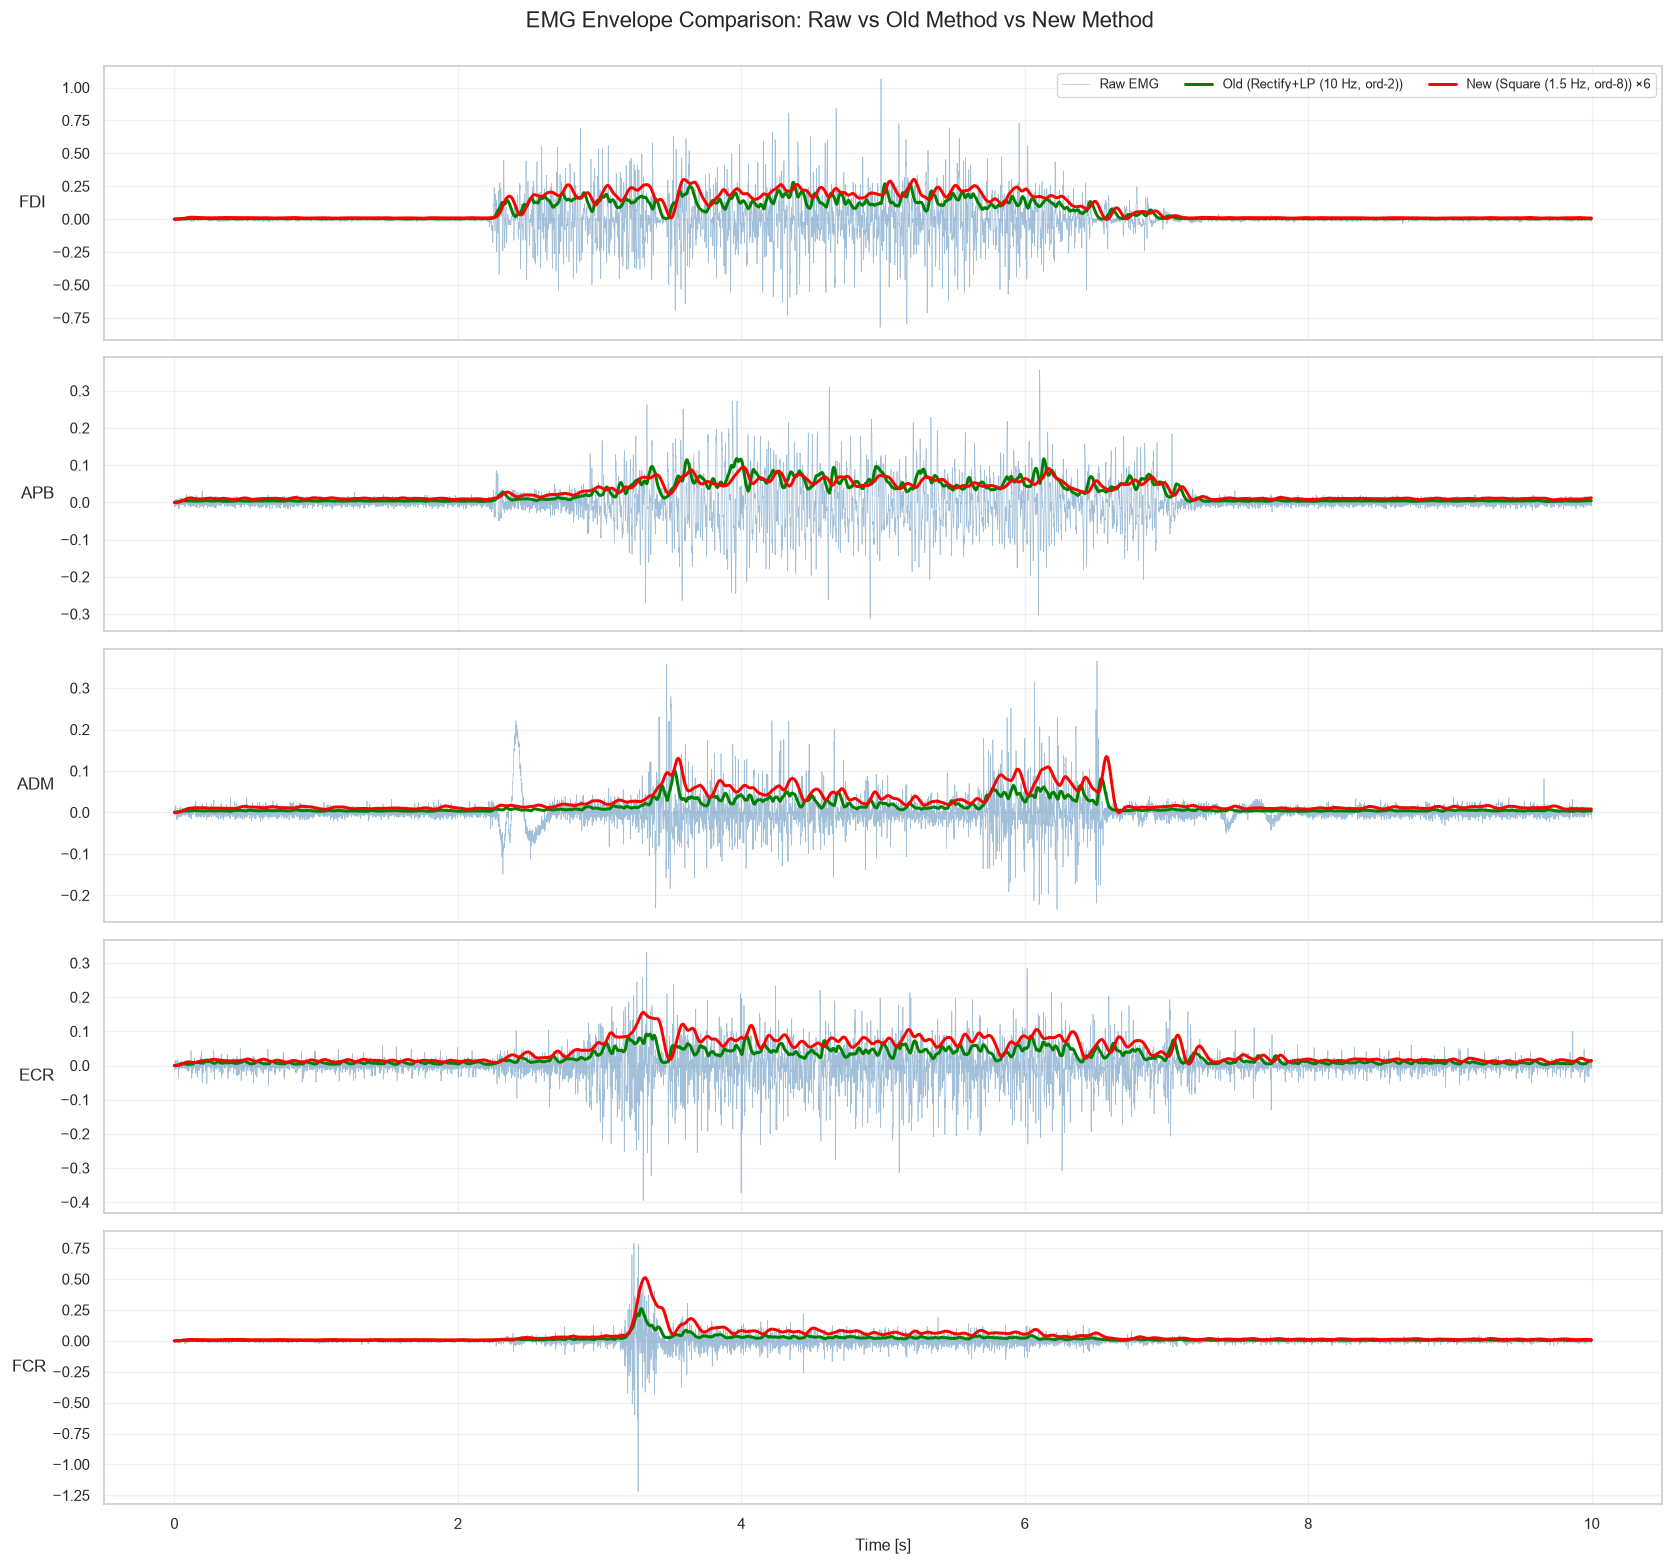

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from main.dataloader import load_hs
from main.preprocessing_emg_kin import preprocess_emg_from_config
from main.plots import plot_emg_envelope_overlay, plot_emg_method_comparison_grid

# 1. Load the continuous series dictionary
data_path = "data/way-eeg/raw/P1/HS_P1_S3.mat"  # Adjust as needed
hs_data = load_hs(data_path)
emg_raw = hs_data["emg"]
fs_raw  = float(hs_data["fs_emg"])
fs_env  = 500.0   # Standard downsampled rate

MUSCLE_NAMES = ["FDI", "APB", "ADM", "ECR", "FCR"]

# 2. Old method baseline (Rectify + 10 Hz LP, 2nd-order)
cfg_old = {
    "bp_low": 30.0, "bp_high": 300.0,
    "lp_cutoff": 10.0, "lp_order": 2,
    "use_tkeo": False,
}
emg_old = preprocess_emg_from_config(emg_raw, fs=fs_raw, cfg=cfg_old)

# 3. New method — square-like bursts (Rectify + 1.5 Hz LP, 8th-order brick-wall)
cfg_new = {
    "bp_low": 30.0, "bp_high": 300.0,
    "lp_cutoff": 8.0, "lp_order": 4,          # ← matches CONFIG
    "use_tkeo": True,
}
emg_square = preprocess_emg_from_config(emg_raw, fs=fs_raw, cfg=cfg_new)

# ── Slice a window ────────────────────────────────────────────────────────────
start_sec, end_sec = 0, 10

start_raw, end_raw = int(start_sec * fs_raw), int(end_sec * fs_raw)
start_env, end_env = int(start_sec * fs_env), int(end_sec * fs_env)

emg_raw_slice    = emg_raw[start_raw:end_raw]
emg_old_slice    = emg_old[start_env:end_env]
emg_square_slice = emg_square[start_env:end_env]

empirical_scale_factor = 6.0   # cosmetic amplitude match for overlay

# ── 5A. Per-muscle overlay (raw + new square envelope) ───────────────────────
emg_square_scaled = emg_square_slice * empirical_scale_factor

for ch in range(emg_raw_slice.shape[1]):
    name = MUSCLE_NAMES[ch] if ch < len(MUSCLE_NAMES) else f"Ch {ch + 1}"
    fig = plot_emg_envelope_overlay(
        raw_emg=emg_raw_slice,
        env_emg=emg_square_scaled,
        fs_raw=fs_raw,
        fs_env=fs_env,
        channel_idx=ch,
        channel_name=name,
        title=f"Square Envelope (1.5 Hz LP, 8th-order) — {name} "
              f"(Scaled ×{empirical_scale_factor} for visualization)",
    )
    plt.show()

# ── 5B. Comparison grid: Old (10 Hz) vs New (1.5 Hz square) ─────────────────
fig_combined = plot_emg_method_comparison_grid(
    raw_emg=emg_raw_slice,
    env_old=emg_old_slice,
    env_new=emg_square_slice,
    fs_raw=fs_raw,
    fs_env=fs_env,
    muscle_names=MUSCLE_NAMES,
    new_method_label="Square (1.5 Hz, ord-8)",
    old_method_label="Rectify+LP (10 Hz, ord-2)",
    new_scale_factor=empirical_scale_factor,
    start_sec=start_sec,
)
plt.show()

Old: 39 cached columns → 36 model features
New: 26 cached columns → 24 model features


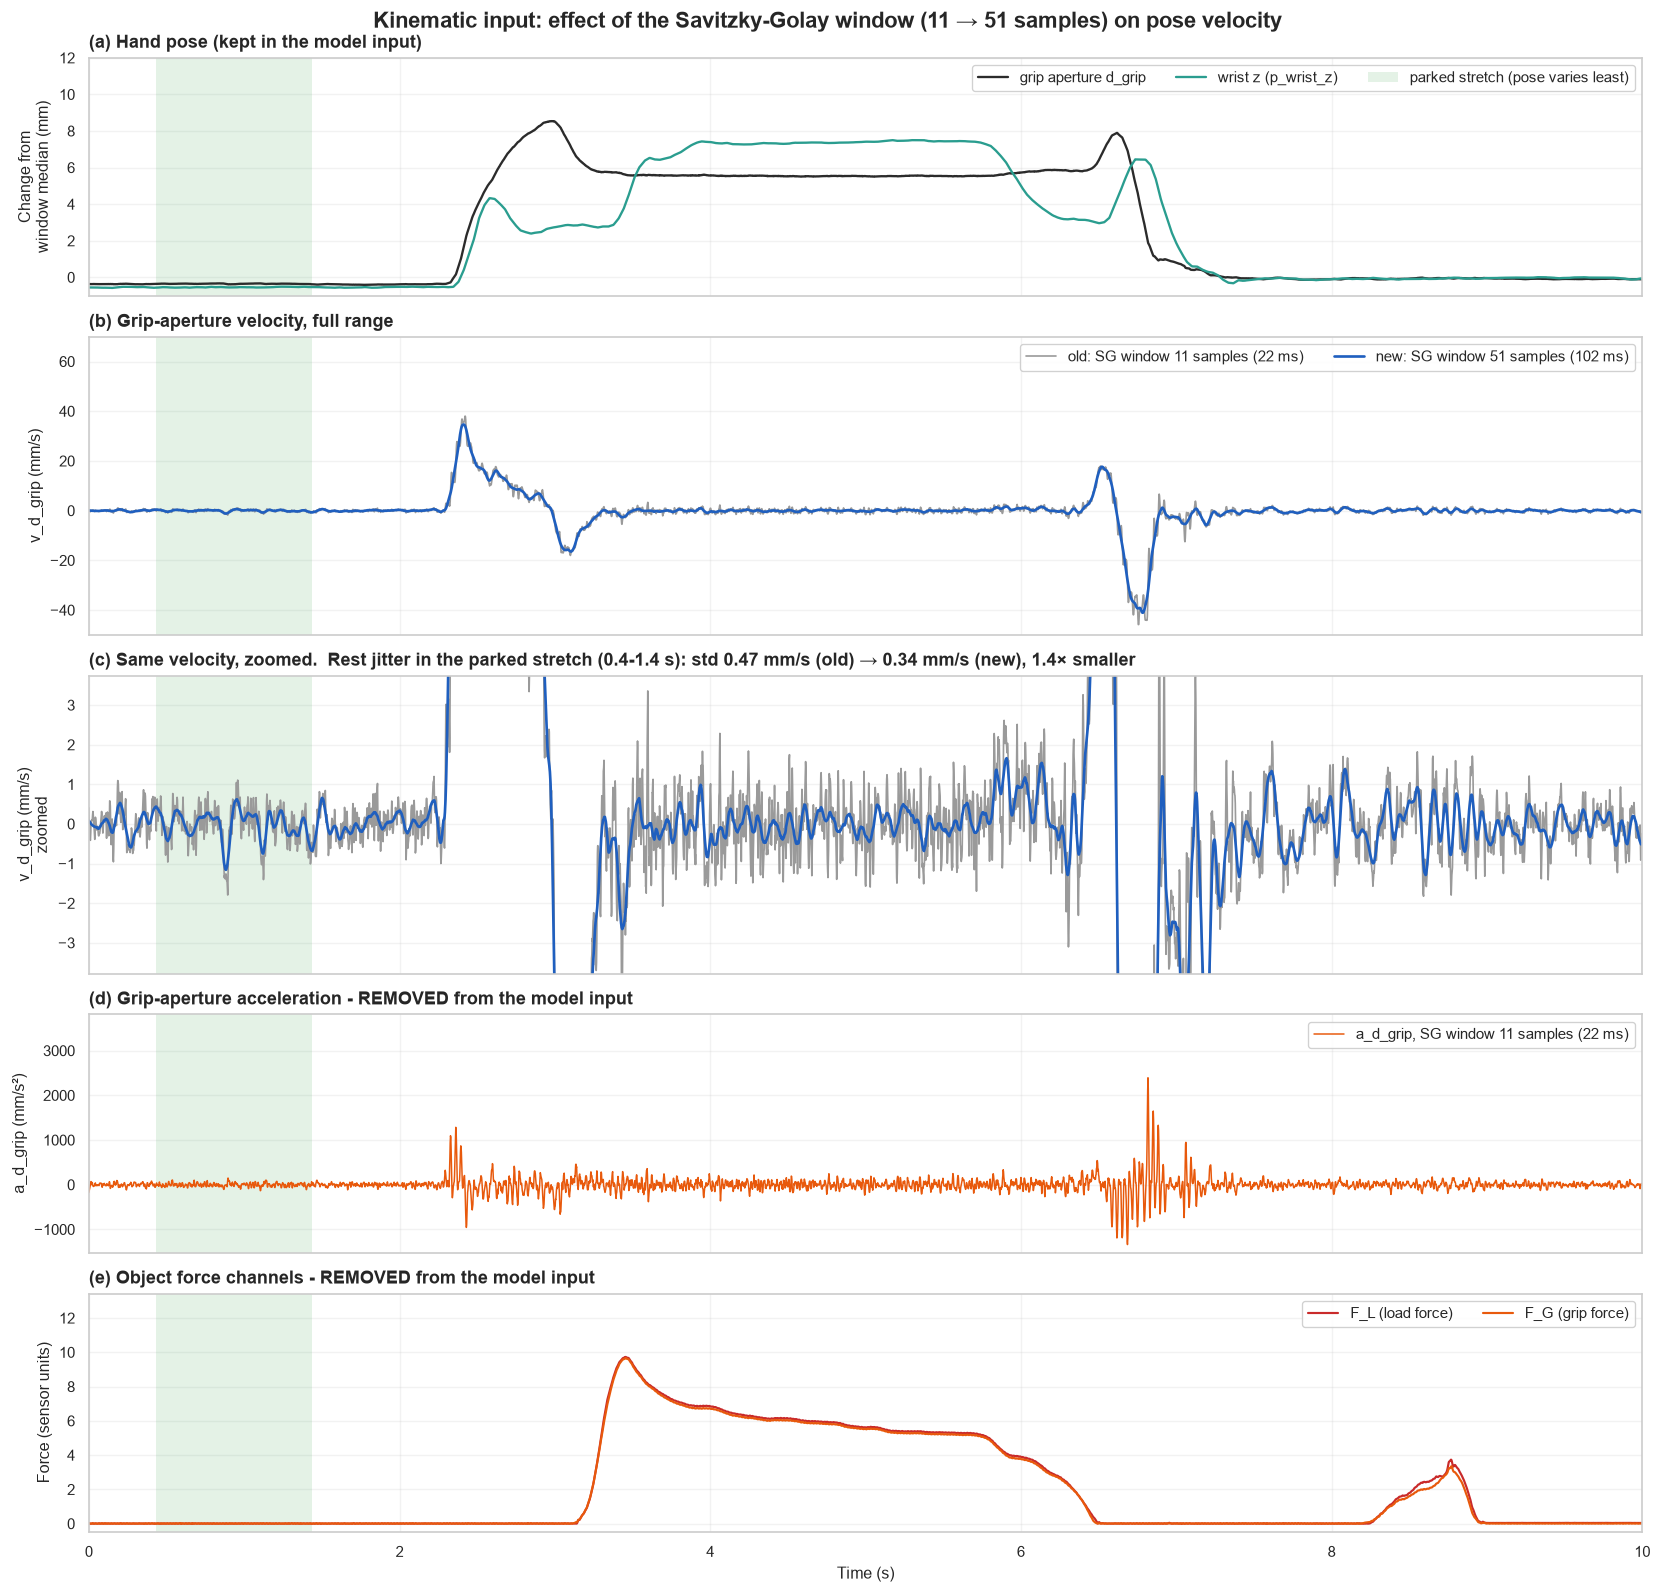

Rest jitter of v_d_grip (0.4-1.4 s): std 0.47 → 0.34 mm/s (1.4× smaller)

Model kinematic input (24 features):
['p_wrist_x', 'p_wrist_y', 'p_wrist_z', 'p_index_x', 'p_index_y', 'p_index_z', 'p_thumb_x', 'p_thumb_y', 'p_thumb_z', 'd_grip', 'F_L_gated', 'F_G_gated', 'v_p_wrist_x', 'v_p_wrist_y', 'v_p_wrist_z', 'v_p_index_x', 'v_p_index_y', 'v_p_index_z', 'v_p_thumb_x', 'v_p_thumb_y', 'v_p_thumb_z', 'v_d_grip', 'v_F_L_gated', 'v_F_G_gated']


In [12]:
import numpy as np
import matplotlib.pyplot as plt
from main.dataloader import load_hs
from main.preprocessing_emg_kin import preprocess_kinematics_from_config, kin_feature_names
from main.plots import plot_kin_smoothing_comparison

# 1. Load the continuous series dictionary
data_path = "data/way-eeg/raw/P1/HS_P1_S3.mat"  # Adjust as needed
hs_data = load_hs(data_path)
kin_raw = hs_data["kin"]            # (T, 36) raw kinematic signal
fs_kin  = float(hs_data["fs_kin"])  # 500 Hz

# 2. New method — hand pose + gated forces + their velocities, SG window 51, no acceleration (= CONFIG)
kin_cfg_new = CONFIG["preprocessing"]["kinematics"]

# 3. Old method baseline — pos + vel + acc, SG window 11, object forces kept
kin_cfg_old = dict(kin_cfg_new, include_acceleration=True, sg_window=11,
                   drop_indices=[12, 25, 38], gated_force=None)

def model_kin_input(kin, kin_cfg):
    """Raw kin → cached columns → columns the model sees (as prepare_batch drops them)."""
    cached = preprocess_kinematics_from_config(kin, fs_kin, kin_cfg)
    return np.delete(cached, kin_cfg["drop_indices"], axis=-1), cached.shape[1]

kin_old, n_cached_old = model_kin_input(kin_raw, kin_cfg_old)
kin_new, n_cached_new = model_kin_input(kin_raw, kin_cfg_new)
print(f"Old: {n_cached_old} cached columns → {kin_old.shape[1]} model features")
print(f"New: {n_cached_new} cached columns → {kin_new.shape[1]} model features")

# ── Slice a window ────────────────────────────────────────────────────────────
start_sec, end_sec = 0, 10

fig = plot_kin_smoothing_comparison(
    kin_raw,
    fs=fs_kin,
    sg_window_old=kin_cfg_old["sg_window"],
    sg_window_new=kin_cfg_new["sg_window"],
    sg_poly=kin_cfg_new["sg_poly"],
    start_sec=start_sec,
    end_sec=end_sec,
)
plt.show()

_j = fig.rest_jitter
print(f"Rest jitter of {_j['signal']} ({_j['rest_start_sec']:.1f}-{_j['rest_end_sec']:.1f} s): "
      f"std {_j['std_old']:.2f} → {_j['std_new']:.2f} {_j['unit']} ({_j['ratio']:.1f}× smaller)")

# Features that go into the model (follows CONFIG)
KIN_INPUT_NAMES = kin_feature_names(
    kin_cfg_new["include_velocity"], kin_cfg_new["include_acceleration"], kin_cfg_new["drop_indices"],
    gated_force=kin_cfg_new.get("gated_force"),
)
print(f"\nModel kinematic input ({len(KIN_INPUT_NAMES)} features):")
print(KIN_INPUT_NAMES)

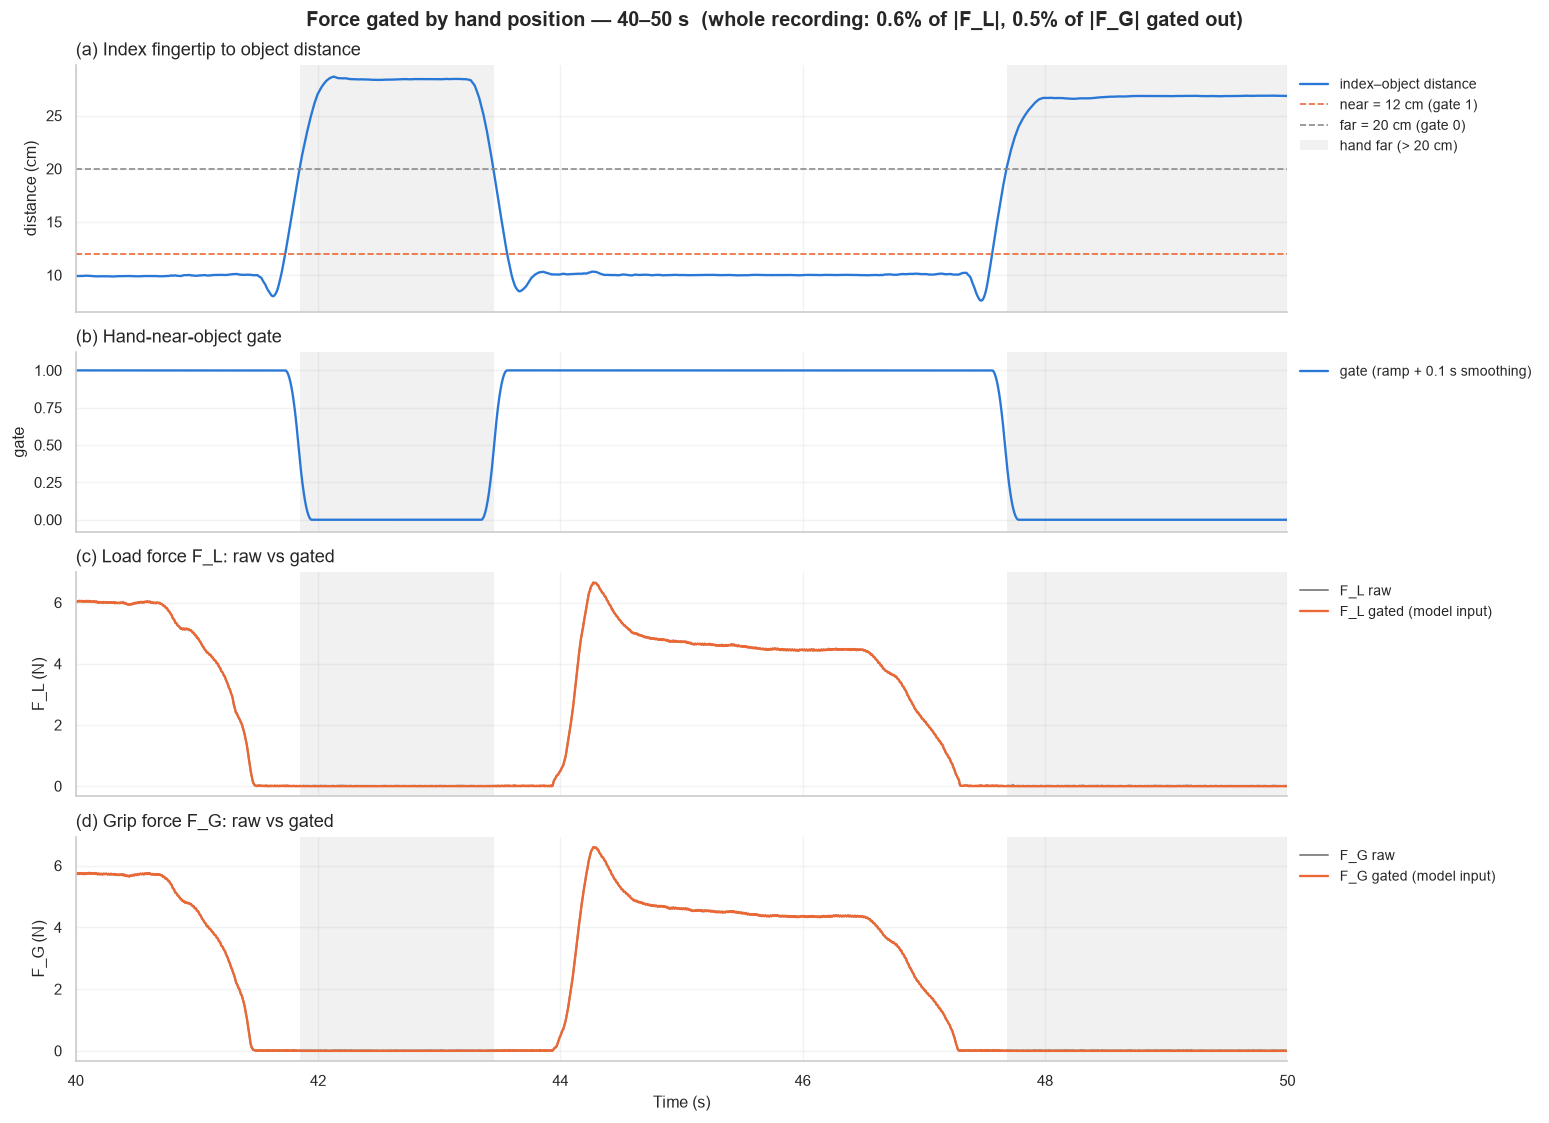

P1 S4: hand near 60% / far 36% of the time | gated out 0.6% of |F_L|, 0.5% of |F_G| | min gate while near = 1.00


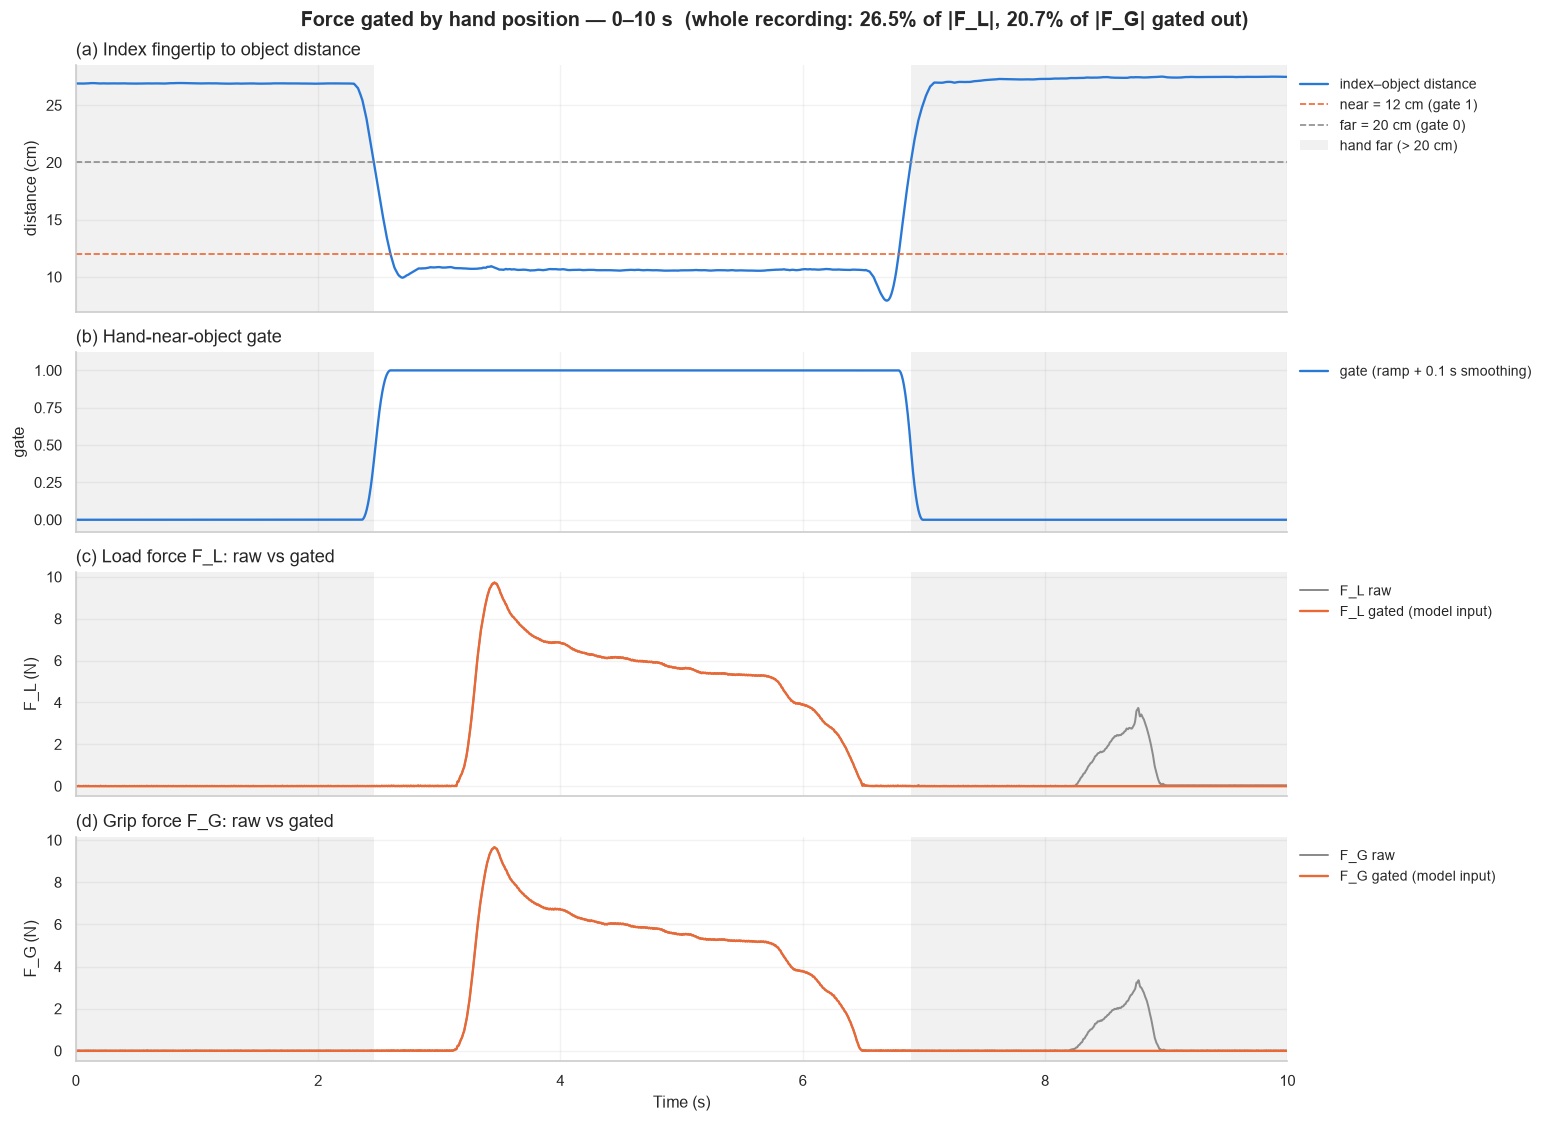

P1 S3: hand near 28% / far 70% of the time | gated out 26.5% of |F_L|, 20.7% of |F_G| | min gate while near = 1.00


In [13]:
# ── Hand-near-object force gate (sanity check: raw .mat only, no model) ─────────
# F_L / F_G are model inputs again, but only while the index fingertip is near the
# object (CONFIG preprocessing.kinematics.gated_force). When the hand is parked,
# someone else loading the object between trials no longer reaches the model.
# Panels: index-object distance with the near / far lines, the gate, raw vs gated forces.
import os
import matplotlib.pyplot as plt
from main.dataloader import load_hs
from main.plots import plot_kin_force_gate

_gate_cfg = CONFIG["preprocessing"]["kinematics"]["gated_force"]
os.makedirs("outputs/kin_gate", exist_ok=True)
for _series, (_t0, _t1) in ((4, (40, 50)), (3, (0, 10))):
    _hs = load_hs(f"data/way-eeg/raw/P1/HS_P1_S{_series}.mat")
    fig = plot_kin_force_gate(_hs["kin"], fs=float(_hs["fs_kin"]), **_gate_cfg,
                              start_sec=_t0, end_sec=_t1)
    fig.savefig(f"outputs/kin_gate/P1_S{_series}_{_t0}s-{_t1}s.png", dpi=130, bbox_inches="tight")
    plt.show()
    _s = fig.gate_stats
    print(f"P1 S{_series}: hand near {100 * _s['near_frac']:.0f}% / far {100 * _s['far_frac']:.0f}% of the time | "
          f"gated out {100 * _s['removed_frac_F_L']:.1f}% of |F_L|, {100 * _s['removed_frac_F_G']:.1f}% of |F_G| | "
          f"min gate while near = {_s['gate_min_near']:.2f}")


In [14]:
def make_preprocess_fn(cfg):
    eeg_cfg = cfg["preprocessing"]["eeg"]
    emg_cfg = cfg["preprocessing"]["emg"]
    kin_cfg = cfg["preprocessing"]["kinematics"]
    def preprocess_fn(series):
        series = dict(series)
        series["eeg"] = preprocess_eeg_from_config(
            series["eeg"],
            float(series["fs_eeg"]),
            eeg_cfg,
            channel_names=series.get("eeg_names"),
        )
        series["emg"] = preprocess_emg_from_config(
            series["emg"],
            float(series["fs_emg"]),
            emg_cfg,
        )
        series["kin"] = preprocess_kinematics_from_config(                                           
              series["kin"],                                                                           
              float(series["fs_kin"]),                                                                 
              kin_cfg,                                                                                 
        ) 
        return series

    return preprocess_fn


def resolve_participants(participant_spec):
    """Resolve participant spec to a list of int IDs.
    
    Accepts:
      "all"        -> [1, 2, ..., 12]
      "P3"         -> [3]
      3            -> [3]
      [1, 2, 3]   -> [1, 2, 3]
      ["P1", "P3"] -> [1, 3]
    """
    ALL_PARTICIPANTS = list(range(1, 13))
    if participant_spec == "all":
        return ALL_PARTICIPANTS
    if isinstance(participant_spec, (list, tuple)):
        return [int(str(p).replace("P", "")) for p in participant_spec]
    # single string like "P2" or int like 2
    return [int(str(participant_spec).replace("P", ""))]


def build_dataset_split(cfg, participants=None, split="train", root_dir=ROOT):
    """Build WAYEEGDataset for the given split.
    
    participants: list of int IDs, or None (uses cfg["data"]["participant"]).
    split: "train" | "val" | "test" | "all" | "stability"
    """
    data_cfg = cfg["data"]
    if participants is None:
        participants = resolve_participants(data_cfg["participant"])
    return WAYEEGDataset(
        data_dir=root_dir / data_cfg["data_root"],
        participants=participants,
        split=split,
        window_size=cfg["dataset"]["window_size"],
        stride=cfg["dataset"]["stride"],
        latency_shift_ms=0.0,
        preprocess_fn=make_preprocess_fn(cfg),
        cache_dir=root_dir / data_cfg["cache_dir"]
    )

# ─────────────────────────────────────────────────────────────────────────────
# Helper utilities (used by both the per-subject loop and LOSOCV loop below)
# ─────────────────────────────────────────────────────────────────────────────

def unique_series_arrays(ds):
    """Return deduplicated (eeg, kin, emg) arrays from a WAYEEGDataset."""
    seen, eegs, kins, emgs = set(), [], [], []
    for eeg_all, kin_all, emg_all, _ in ds._windows:
        key = id(eeg_all)
        if key in seen:
            continue
        seen.add(key)
        eegs.append(eeg_all)
        kins.append(kin_all)
        emgs.append(emg_all)
    return eegs, kins, emgs


def local_prepare_batch_factory(emg_mean, emg_std, kin_mean, kin_std, device,
                                drop_kin_indices=None):
    """Return a per-subject prepare_batch closure with frozen normalization stats."""
    def prepare_batch(eeg, kin, emg):
        eeg = eeg.to(device, non_blocking=True)
        kin = kin.to(device, non_blocking=True)
        emg = emg.to(device, non_blocking=True)
        kin_norm = (kin - kin_mean) / kin_std
        if drop_kin_indices is not None:
            keep_idx = [i for i in range(kin_norm.shape[-1]) if i not in drop_kin_indices]
            kin_norm = kin_norm[..., keep_idx]
        emg_norm = (emg - emg_mean) / emg_std
        return {"eeg": eeg, "kin": kin_norm}, emg_norm
    return prepare_batch


# ─────────────────────────────────────────────────────────────────────────────
# SINGLE-STAGE TRAINING ROUTINE (used by the per-subject loop and LOSOCV below)
# ─────────────────────────────────────────────────────────────────────────────
def train_single_stage(cfg, subj, eeg_dim, kin_dim, edge_prior,
                       train_loader, val_loader, prepare_batch, loss_fn, device):
    """Train the full KG-GT model jointly in ONE stage (no Transformer-only
    pre-training, nothing frozen).

    Hyper-parameters: lr / epochs from cfg["training"]["single_stage"]; optimizer,
    scheduler (cosine), warmup_epochs, transformer_lr_scale, early_stop_patience,
    grad clipping, AMP and grad accumulation from the shared cfg["training"] keys.
    Checkpoints: {cfg["training"]["checkpoint_dir"]}/{subj}/ (last.pt + best.pt);
    an interrupted run resumes from last.pt.

    Returns (end_of_training_model, best_model, TrainResult, ckpt_dir).
    """
    tr = cfg["training"]
    ss = tr["single_stage"]
    ckpt_dir = str(Path(tr["checkpoint_dir"]) / subj)
    # never write into the two-stage notebook's folders
    assert "checkpoints_main" not in Path(ckpt_dir).as_posix(), ckpt_dir

    model = build_kg_gt_from_config(
        cfg, input_dim=eeg_dim, kin_dim=kin_dim, edge_prior=edge_prior,
    ).to(device)
    for p in model.parameters():          # everything trainable from the start
        p.requires_grad = True
    n_all = sum(p.numel() for p in model.parameters())
    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    assert n_trainable == n_all

    tc = TrainConfig.from_config(tr, max_epochs=ss["epochs"], lr=ss["lr"])
    tc.checkpoint_dir = ckpt_dir
    print(f"  Trainable parameters : {n_trainable:,} / {n_all:,}")
    print(f"  Optimizer / schedule : {tc.optimizer} | {tc.scheduler} | warmup {tc.warmup_epochs} ep "
          f"| lr {tc.lr:.1e} (encoder x{tc.transformer_lr_scale}) | max {tc.max_epochs} ep "
          f"| early-stop patience {tc.early_stop_patience}")
    print(f"  Checkpoints          : {ckpt_dir}")

    result = train_model(
        model=model,
        train_loader=train_loader,
        val_loader=val_loader,
        prepare_batch=prepare_batch,
        loss_fn=loss_fn,
        device=device,
        cfg=tc,
        resume=True,
    )

    # ── Load BEST checkpoint from disk into a clean model copy ────────────
    best = copy.deepcopy(model)
    best_path = Path(ckpt_dir) / "best.pt"
    if best_path.exists():
        load_checkpoint(str(best_path), best, device)
        print(f"  Loaded best checkpoint: {best_path}")
    else:
        print(f"  [WARNING] best.pt not found at {best_path}; using end-of-training weights.")
    best.eval()
    return model, best, result, ckpt_dir


In [15]:
# ============================================================================
# PER-SUBJECT PRE-PROCESSING LOOP
# ============================================================================
# This cell runs BEFORE training.  For each subject it:
#   1. Builds train / val / test WAYEEGDatasets  (uses cache_dir → loads fast
#      on second run because the dataset caches preprocessed arrays to disk)
#      Split is per participant and condition-stratified (from P{p}_AllLifts.mat):
#        test  = later W + later B of series 1-6              -> {W, B}
#        val   = series 9                                     -> {W}
#        train = earlier W of 1-6, S7, S8, both S, earlier B  -> {3W, 2S, 1B}
#      (W = weight varies, S = surface varies, B = both vary)
#   2. Computes per-subject normalization stats (emg_mean/std, kin_mean/std)
#   3. Builds the prepare_batch closure
#   4. Stores everything in `subject_data[f"P{p_id}"]`
#
# Edit `subject_list` ↓ to choose which subjects to process.
# ─────────────────────────────────────────────────────────────────────────────
import gc, os, time
import numpy as np
import torch
from torch.utils.data import DataLoader
from main.losses import channel_weights_from_config

# ── USER CONFIG ───────────────────────────────────────────────────────────────
subject_list = [1]   # ← EDIT: list of participant IDs to process/train

# ─────────────────────────────────────────────────────────────────────────────
subject_data = {}   # populated below; keyed by "P{id}"

for p_id in subject_list:
    _t0 = time.time()
    _subj = f"P{p_id}"
    print(f"\n{'='*70}")
    print(f"  PRE-PROCESSING SUBJECT {_subj}")
    print(f"{'='*70}")

    # ── 1. Per-subject config ──────────────────────────────────────────────
    _cfg = copy.deepcopy(notebook_cfg)
    _cfg["data"]["participant"] = p_id

    # ── 2. Build datasets (cached on disk → fast after first run) ─────────
    _train_ds = build_dataset_split(_cfg, participants=[p_id], split="train")
    _val_ds   = build_dataset_split(_cfg, participants=[p_id], split="val")
    _test_ds  = build_dataset_split(_cfg, participants=[p_id], split="test")

    print(f"  Train windows : {len(_train_ds)}")
    print(f"  Val   windows : {len(_val_ds)}")
    print(f"  Test  windows : {len(_test_ds)}")
    print(describe_split(p_id, ROOT / _cfg["data"]["data_root"]))

    # ── 3. Compute normalization stats from training data ──────────────────
    _train_eegs, _train_kins, _train_emgs = unique_series_arrays(_train_ds)

    _kin_all = np.concatenate(_train_kins, axis=0)
    _emg_all = np.concatenate(_train_emgs, axis=0)

    _emg_mean = torch.tensor(_emg_all.mean(axis=0), dtype=torch.float32, device=device)
    _emg_std  = torch.tensor(_emg_all.std(axis=0),  dtype=torch.float32, device=device)
    _kin_mean = torch.tensor(_kin_all.mean(axis=0), dtype=torch.float32, device=device)
    _kin_std  = torch.tensor(_kin_all.std(axis=0),  dtype=torch.float32, device=device)

    _emg_std = torch.clamp(_emg_std, min=1e-6)
    _kin_std = torch.clamp(_kin_std, min=1e-6)

    # ── 4. Build prepare_batch closure (captures per-subject stats) ───────
    _drop_indices = _cfg["preprocessing"]["kinematics"]["drop_indices"]
    _prepare_batch = local_prepare_batch_factory(
        _emg_mean, _emg_std, _kin_mean, _kin_std, device,
        drop_kin_indices=_drop_indices,
    )

    # ── 5. Infer model input dimensions ───────────────────────────────────
    _sample_eeg, _sample_kin, _sample_emg = _train_ds[0]
    _dummy_eeg = torch.as_tensor(_sample_eeg).unsqueeze(0)
    _dummy_kin = torch.as_tensor(_sample_kin).unsqueeze(0)
    _dummy_emg = torch.as_tensor(_sample_emg).unsqueeze(0)
    _batch_in, _ = _prepare_batch(_dummy_eeg, _dummy_kin, _dummy_emg)
    _true_eeg_dim = _sample_eeg.shape[-1]
    _true_kin_dim = _batch_in["kin"].shape[-1]

    # ── 6. Edge prior + loss ───────────────────────────────────────────────
    _prior_np   = compute_muscle_edge_prior(_train_emgs)
    _edge_prior = torch.from_numpy(_prior_np)
    # Per-muscle loss weights (loss.channel_weights): "auto" → w_c ∝ 1/p95(|z_c|) of the
    # z-scored TRAINING targets (same mean/std as prepare_batch), normalised to mean 1.
    _emg_z = (_emg_all - _emg_mean.cpu().numpy()) / _emg_std.cpu().numpy()
    _channel_weights = channel_weights_from_config(_cfg["training"], _emg_z)
    del _emg_z
    if _channel_weights is not None:
        print("  Loss channel weights: " + ", ".join(
            f"{_n}={_w:.2f}" for _n, _w in zip(["FDI", "APB", "ADM", "ECR", "FCR"], _channel_weights)))
    _loss_fn    = build_loss_from_config(_cfg["training"], channel_weights=_channel_weights)

    # ── 7. DataLoaders ────────────────────────────────────────────────────
    _bs = _cfg["training"]["batch_size"]
    _train_loader = DataLoader(_train_ds, batch_size=_bs, shuffle=True,
                               drop_last=True, pin_memory=True, num_workers=0)
    _val_loader   = DataLoader(_val_ds,   batch_size=_bs, shuffle=False,
                               pin_memory=True, num_workers=0)
    _test_loader  = DataLoader(_test_ds,  batch_size=_bs, shuffle=False,
                               pin_memory=True, num_workers=0)

    # ── 8. Store ──────────────────────────────────────────────────────────
    subject_data[_subj] = dict(
        cfg=_cfg,
        train_ds=_train_ds, val_ds=_val_ds, test_ds=_test_ds,
        train_loader=_train_loader, val_loader=_val_loader, test_loader=_test_loader,
        emg_mean=_emg_mean, emg_std=_emg_std,
        kin_mean=_kin_mean, kin_std=_kin_std,
        prepare_batch=_prepare_batch,
        edge_prior=_edge_prior, loss_fn=_loss_fn,
        true_eeg_dim=_true_eeg_dim, true_kin_dim=_true_kin_dim,
        train_emgs=_train_emgs,
        drop_indices=_drop_indices,
        channel_weights=_channel_weights,
    )

    elapsed = time.time() - _t0
    print(f"  [{_subj}] Pre-processing done in {elapsed:.1f}s")

print(f"\n✓  subject_data ready for {list(subject_data.keys())}")



  PRE-PROCESSING SUBJECT P1
  Train windows : 2188
  Val   windows : 231
  Test  windows : 653
P1 stratified split (W=weight, S=surface, B=both varies):
  train [S1:W, S2:S, S3:B, S6:S, S7:W, S8:W]  lifts=198
  val   [S9:W]  lifts=34
  test  [S4:W, S5:B]  lifts=62
  Loss channel weights: FDI=1.07, APB=1.01, ADM=0.96, ECR=1.01, FCR=0.95
  [P1] Pre-processing done in 2.5s

✓  subject_data ready for ['P1']



  TRAINING P1  (fold 1/1)

--- SINGLE-STAGE: Full KG-GT joint training [P1] ---
  Mean-predictor baseline MSE: 3.6638
  Trainable parameters : 1,211,107 / 1,211,107
  Optimizer / schedule : adamw | cosine | warmup 5 ep | lr 1.0e-03 (encoder x0.1) | max 200 ep | early-stop patience 25
  Checkpoints          : outputs\checkpoints_1stage\P1
  Differential LR groups:
    GAT/Decoder  : 1.00e-03
    Transformer  : 1.00e-04  (scale=0.1)
    KinSkip      : 3.33e-04  (regularized)

  GPU / Device Status
  OK  Device index    : cuda:0
  OK  GPU name        : NVIDIA GeForce GTX 1660 Ti
  OK  CUDA capability : sm_75
  OK  VRAM (total)    : 6,144 MB
  OK  VRAM allocated  : 162.4 MB
  OK  VRAM reserved   : 1974.0 MB
  OK  CUDA version    : 12.6
  OK  PyTorch build   : 2.8.0+cu126
  OK  AMP (FP16)      : YES -- Turing tensor cores active
  Optimizer : ADAMW  (weight_decay=0.01)
  Scheduler : COSINE  (T_max=200, eta_min=1e-06)

Resumed from checkpoint: outputs\checkpoints_1stage\P1\last.pt
  Complet

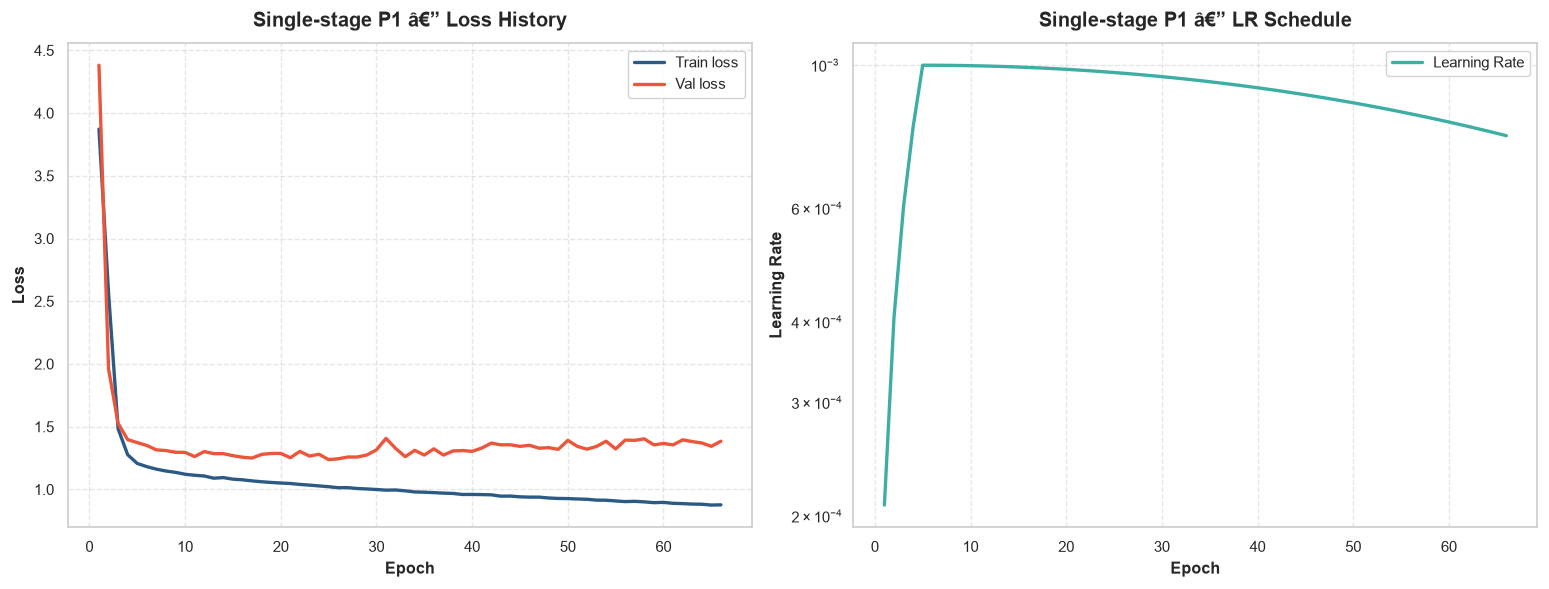


  [P1] Complete in 0.1 min

[!] Global scope updated with last subject (P1) variables.

  ALL SUBJECTS TRAINED (single stage): ['P1']


In [16]:
# ============================================================================
# PER-SUBJECT TRAINING LOOP  (SINGLE STAGE — full KG-GT trained jointly)
# ============================================================================
# Iterates over subject_data (populated by the pre-processing loop above).
# For each subject the full KG-GT model (encoder + node projection + GAT +
# decoder + kin skip highway) is trained ONCE, from scratch, with every
# parameter trainable (see train_single_stage in the helper cell).
#
# Checkpoints are saved to:
#   outputs/checkpoints_1stage/{subject}/   (last.pt + best.pt, resumable)
#
# After the loop, the LAST subject's variables are exported to global scope
# so all downstream single-subject cells (evaluation, interpretability) work
# without modification.
#
# Results are collected in `per_subject_results` dict keyed by "P{id}".
# For compatibility with cells written for the two-stage notebook,
# stage1_model is None and result_stage1 / result_stage2 both hold the single
# training result (also available as result_single).
# ─────────────────────────────────────────────────────────────────────────────
from main.training import compute_mean_baseline_loss
from main.plots import plot_training_history
import gc, time
from pathlib import Path

per_subject_results = {}   # keyed by "P{id}"

for _fold_idx, (_subj, _sd) in enumerate(subject_data.items()):
    _t_fold = time.time()
    print(f"\n{'='*70}")
    print(f"  TRAINING {_subj}  (fold {_fold_idx + 1}/{len(subject_data)})")
    print(f"{'='*70}")

    _cfg          = _sd["cfg"]
    _train_loader = _sd["train_loader"]
    _val_loader   = _sd["val_loader"]
    _test_loader  = _sd["test_loader"]
    _train_ds     = _sd["train_ds"]
    _val_ds       = _sd["val_ds"]
    _test_ds      = _sd["test_ds"]
    _prepare_batch= _sd["prepare_batch"]
    _emg_mean     = _sd["emg_mean"]
    _emg_std      = _sd["emg_std"]
    _kin_mean     = _sd["kin_mean"]
    _kin_std      = _sd["kin_std"]
    _edge_prior   = _sd["edge_prior"]
    _loss_fn      = _sd["loss_fn"]
    _eeg_dim      = _sd["true_eeg_dim"]
    _kin_dim      = _sd["true_kin_dim"]

    # ── SINGLE STAGE: full KG-GT joint training ───────────────────────────
    print(f"\n--- SINGLE-STAGE: Full KG-GT joint training [{_subj}] ---")
    _baseline_mse = compute_mean_baseline_loss(
        _train_loader, loss_fn=_loss_fn, device=device, prepare_batch=_prepare_batch
    )
    print(f"  Mean-predictor baseline MSE: {_baseline_mse:.4f}")

    _model, _bm, _r, _ckpt_dir = train_single_stage(
        _cfg, _subj, _eeg_dim, _kin_dim, _edge_prior,
        _train_loader, _val_loader, _prepare_batch, _loss_fn, device,
    )
    print(f"  Single-stage final train loss : {_r.history['train'][-1]:.4f}")
    print(f"  Single-stage final val   loss : {_r.history['val'][-1]:.4f}")
    print(f"  Best val loss                 : {_r.best_val:.4f}")

    _fig_hist = plot_training_history(_r.history, stage=f"Single-stage {_subj}", cfg=_cfg)
    plt.show()

    # ── Store results ──────────────────────────────────────────────────────
    per_subject_results[_subj] = dict(
        model=_bm,
        stage1_model=None,                 # no Stage 1 in this notebook
        train_ds=_train_ds, val_ds=_val_ds, test_ds=_test_ds,
        train_loader=_train_loader, val_loader=_val_loader, test_loader=_test_loader,
        prepare_batch=_prepare_batch,
        emg_mean=_emg_mean, emg_std=_emg_std,
        kin_mean=_kin_mean, kin_std=_kin_std,
        result_stage1=_r, result_stage2=_r, result_single=_r,
        cfg=_cfg,
        edge_prior=_edge_prior,
        true_eeg_dim=_eeg_dim,
        true_kin_dim=_kin_dim,
        checkpoint_dir=_ckpt_dir,
    )

    elapsed = (time.time() - _t_fold) / 60.0
    print(f"\n  [{_subj}] Complete in {elapsed:.1f} min")

    # ── After last subject: export to global scope for downstream cells ────
    if _fold_idx == len(subject_data) - 1:
        model         = _model
        best_model    = _bm
        stage1_model  = None
        train_ds      = _train_ds
        val_ds        = _val_ds
        test_ds       = _test_ds
        train_loader  = _train_loader
        val_loader    = _val_loader
        test_loader   = _test_loader
        prepare_batch = _prepare_batch
        emg_mean      = _emg_mean
        emg_std       = _emg_std
        kin_mean      = _kin_mean
        kin_std       = _kin_std
        result_single = _r
        result_stage1 = _r
        result_stage2 = _r
        subject_str   = _subj
        edge_prior    = _edge_prior
        true_eeg_dim  = _eeg_dim
        true_kin_dim  = _kin_dim
        notebook_cfg  = _cfg
        print(f"\n[!] Global scope updated with last subject ({_subj}) variables.")
    else:
        # Free GPU memory between subjects
        del _model, _bm
        torch.cuda.empty_cache()
        gc.collect()

print(f"\n{'='*70}")
print(f"  ALL SUBJECTS TRAINED (single stage): {list(per_subject_results.keys())}")
print(f"{'='*70}")


In [17]:
# EVALUATION — Full metric suite: RMSE, nRMSE, MAE, Pearson r, R²,  VAF
#              Per-subject loop  →  saves results/evaluation_report.md
import copy, os, datetime
import torch
import numpy as np
import pandas as pd
from main import collect_predictions, compute_metrics, load_checkpoint

EMG_NAMES = ["FDI", "APB", "ADM", "ECR", "FCR"]   # adjust to your dataset labels
REPORT_PATH = "results/evaluation_report_1stage.md"   # main.ipynb writes evaluation_report.md
os.makedirs("results", exist_ok=True)

# ── Decide which subjects to evaluate ────────────────────────────────────────
# If per_subject_results exists (multi-subject loop was run), evaluate all of them.
# Otherwise fall back to the single-subject global variables.
if "per_subject_results" in dir() and per_subject_results:
    _eval_subjects = per_subject_results
else:
    # Wrap single-subject globals into the same dict structure
    _eval_subjects = {
        subject_str: dict(
            model=best_model,
            test_loader=test_loader,
            prepare_batch=prepare_batch,
            cfg=notebook_cfg,
        )
    }

all_rows   = []   # one row per (subject, channel)
mean_rows  = []   # one row per subject  (mean across channels)
subject_dfs = {}  # full DataFrame per subject

for _subj, _res in _eval_subjects.items():
    _cfg          = _res["cfg"]
    _test_loader  = _res["test_loader"]
    _pb           = _res["prepare_batch"]

    # ── Load best checkpoint from disk into a clean model copy ───────────
    _bm = copy.deepcopy(_res["model"])
    _ckpt = os.path.join(_cfg["training"]["checkpoint_dir"], _subj, "best.pt")   # single-stage
    if os.path.exists(_ckpt):
        load_checkpoint(_ckpt, _bm, device)
        print(f"[{_subj}] Loaded best checkpoint: {_ckpt}")
    else:
        print(f"[{_subj}] WARNING: best.pt not found at {_ckpt} — using in-memory weights.")
    _bm.eval()

    # ── Collect predictions ───────────────────────────────────────────────
    P_test, Y_test = collect_predictions(
        _bm, _test_loader, _pb, device,
        n_channels=len(EMG_NAMES),
        use_amp=_cfg["training"].get("use_amp", False),
    )

    # ── Compute metrics ───────────────────────────────────────────────────
    _m = compute_metrics(P_test, Y_test, channel_names=EMG_NAMES)

    # ── Print ASCII table ─────────────────────────────────────────────────
    print(f"\n{'─'*60}")
    print(f"  {_subj}")
    print(f"{'─'*60}")
    print(_m.as_table())

    _vaf_pass = int((_m.vaf >= 80.0).sum())
    print(f"VAF >= 80%: {_vaf_pass}/{len(EMG_NAMES)} channels")

    # ── Build per-subject DataFrame ───────────────────────────────────────
    _rows = list(zip(
        _m.channel_names,
        _m.rmse.tolist(), _m.nrmse.tolist(), _m.mae.tolist(),
        _m.pearson.tolist(), _m.ccc.tolist(), _m.r2.tolist(), _m.vaf.tolist(),
    ))
    _df = pd.DataFrame(
        _rows,
        columns=["Channel", "RMSE", "nRMSE%", "MAE", "Pearson_r", "CCC", "R2", "VAF%"],
    )
    _mean_vals = _df[[c for c in _df.columns if c != "Channel"]].mean()
    _mean_row  = pd.DataFrame([["MEAN"] + _mean_vals.tolist()], columns=_df.columns)
    _df_full   = pd.concat([_df, _mean_row], ignore_index=True)
    subject_dfs[_subj] = _df_full

    # Accumulate for cross-subject summary
    for _, r in _df.iterrows():
        all_rows.append({"Subject": _subj, **r.to_dict()})
    mean_rows.append({
        "Subject": _subj,
        "RMSE":      float(_mean_vals["RMSE"]),
        "nRMSE%":    float(_mean_vals["nRMSE%"]),
        "MAE":       float(_mean_vals["MAE"]),
        "Pearson_r": float(_mean_vals["Pearson_r"]),
        "CCC":       float(_mean_vals["CCC"]),
        "R2":        float(_mean_vals["R2"]),
        "VAF%":      float(_mean_vals["VAF%"]),
        "VAF>=80":   f"{_vaf_pass}/{len(EMG_NAMES)}",
    })

    # Update global scope to last evaluated subject (keeps downstream cells working)
    best_model    = _bm
    test_loader   = _test_loader
    prepare_batch = _pb
    notebook_cfg  = _cfg
    subject_str   = _subj
    metrics       = _m
    df            = _df_full

# ── Cross-subject summary ─────────────────────────────────────────────────────
summary_df = pd.DataFrame(mean_rows)
num_cols   = [c for c in summary_df.columns if c not in ("Subject", "VAF>=80")]
_grand     = summary_df[num_cols].mean().to_dict()
_grand.update({"Subject": "GRAND MEAN", "VAF>=80": "—"})
summary_df = pd.concat([summary_df, pd.DataFrame([_grand])], ignore_index=True)

print("\n" + "="*65)
print("  CROSS-SUBJECT SUMMARY (mean across channels per subject)")
print("="*65)
print(summary_df.round(4).to_string(index=False))

# ── Build & save Markdown report ──────────────────────────────────────────────
def _df_to_md(df: pd.DataFrame) -> str:
    """Render a DataFrame as a GitHub-Flavoured Markdown table."""
    header = "| " + " | ".join(str(c) for c in df.columns) + " |"
    sep    = "| " + " | ".join(["---"] * len(df.columns)) + " |"
    rows   = []
    for _, row in df.iterrows():
        cells = []
        for v in row:
            if isinstance(v, float):
                cells.append(f"{v:.4f}")
            else:
                cells.append(str(v))
        rows.append("| " + " | ".join(cells) + " |")
    return "\n".join([header, sep] + rows)

_ts  = datetime.datetime.now().strftime("%Y-%m-%d %H:%M")
_md  = f"# EMG Decoding Evaluation Report (single-stage KG-GT)\n\n"
_md += f"**Generated:** {_ts}  \n"
_md += f"**Subjects:** {list(subject_dfs.keys())}  \n"
_md += f"**Channels:** {EMG_NAMES}  \n\n"
_md += "---\n\n"

# Per-subject tables
for _subj, _df_full in subject_dfs.items():
    _vaf_p = int((_df_full.loc[_df_full["Channel"] != "MEAN", "VAF%"].astype(float) >= 80.0).sum())
    _md += f"## {_subj}\n\n"
    _md += _df_to_md(_df_full.round(4)) + "\n\n"
    _md += f"> VAF ≥ 80%: **{_vaf_p}/{len(EMG_NAMES)} channels**\n\n"
    _md += "---\n\n"

# Cross-subject summary
_md += "## Cross-Subject Summary\n\n"
_md += "> One row per subject (mean across all channels). "
_md += "GRAND MEAN is the average over all subjects.\n\n"
_md += _df_to_md(summary_df.round(4)) + "\n"

with open(REPORT_PATH, "w", encoding="utf-8") as _f:
    _f.write(_md)

print(f"\n✓  Markdown report saved → {REPORT_PATH}")


Loaded checkpoint <- outputs/checkpoints_1stage\P1\best.pt  (best_val=1.2548)
[P1] Loaded best checkpoint: outputs/checkpoints_1stage\P1\best.pt

────────────────────────────────────────────────────────────
  P1
────────────────────────────────────────────────────────────
Channel                RMSE   nRMSE%      MAE  Pearson r      CCC      R^2     VAF%
-----------------------------------------------------------------------------------
FDI                  0.3545     5.93   0.2194     0.9451   0.9408   0.8763    88.44
APB                  0.4402     4.78   0.2553     0.9145   0.9037   0.8323    83.34
ADM                  0.7188     5.39   0.3970     0.7766   0.7278   0.5905    59.80
ECR                  0.5297     6.36   0.4190     0.8963   0.8505   0.7644    78.13
FCR                  0.3889     3.10   0.2014     0.9227   0.9209   0.8497    85.08
-----------------------------------------------------------------------------------
 MEAN                0.4864     5.11   0.2984     0.891


──────────────────────────────────────────────────────────────────────────────────────────
  P1 — magnitude per test series (original EMG units)
──────────────────────────────────────────────────────────────────────────────────────────
       group muscle     r   ccc    rmse VAF% height rest_pred rest_tgt  over under
series 4 (W)    FDI 0.914 0.904 0.00723 82.8  0.963   0.00228   0.0015 0.190 0.067
                APB 0.881 0.856 0.00256 77.0  0.821   0.00182  0.00164 0.077 0.145
                ADM 0.764 0.623 0.00387 55.8  0.599   0.00191  0.00164 0.047 0.319
                ECR 0.863 0.820 0.00332 72.7  0.825   0.00534  0.00315 0.092 0.133
                FCR 0.920 0.918 0.00556 84.7  0.985   0.00223  0.00162 0.163 0.123
               MEAN 0.868 0.824 0.00451 74.6  0.839   0.00271  0.00191 0.114 0.158
series 5 (B)    FDI 0.959 0.956 0.00432 91.1  1.075   0.00174  0.00134 0.165 0.081
                APB 0.925 0.921 0.00141 85.5  0.965   0.00169   0.0013 0.111 0.104
                

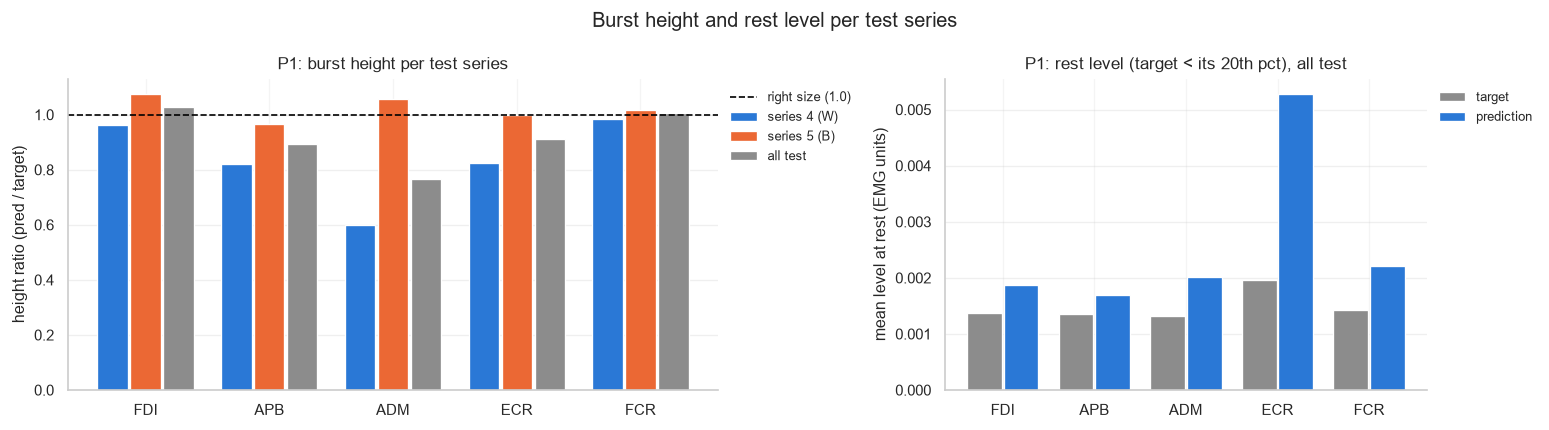

✓  Saved results/magnitude_report_1stage.csv and results/magnitude_report_1stage.png


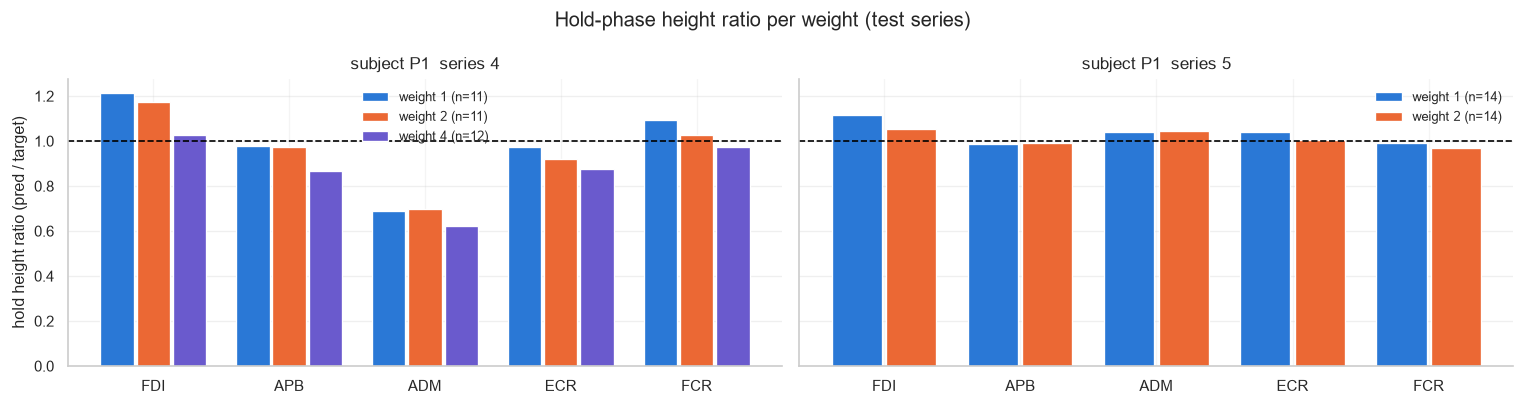

✓  Saved results/magnitude_by_load_1stage.csv and results/magnitude_by_load_1stage.png


In [18]:
# ============================================================================
# MAGNITUDE EVALUATION — per test series and per condition (original EMG units)
# ============================================================================
# Pearson r does not show whether bursts have the right SIZE or whether the
# prediction returns to baseline. For each subject every test series is run
# through the best model in consecutive non-overlapping windows (window_size,
# same prepare_batch / normalisation as training; the tail shorter than one
# window is dropped), stitched and denormalised (x * emg_std + emg_mean). Per muscle:
#   height  Σ(pred·active) / Σ(target·active), active = target > its 70th pct (1 = right size)
#   rest    mean pred where target < its 20th pct, next to the mean target there
#   over    Σ relu(pred − target) / Σ target     under  Σ relu(target − pred) / Σ target
#   plus r, CCC, RMSE, VAF%.
# Rows: "series 4 (W)", "series 5 (B)", ..., "all test"  (W = weight varies,
# S = surface varies, B = both vary). Saves results/magnitude_report_1stage.csv / .png
# Per weight / per surface: mean level over the HOLD phase of every lift
# (P{p}_AllLifts.mat: lift-off + 0.3 s … replace − 0.3 s): n lifts, target and
# predicted hold level, height ratio Σpred/Σtarget, per-lift r (NaN < 4 lifts).
# Saves results/magnitude_by_load_1stage.csv / .png (height ratio per muscle per weight).
# ─────────────────────────────────────────────────────────────────────────────
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from main import (
    get_split_series, series_conditions,
    predict_series, magnitude_report_by_series, format_magnitude_table, plot_magnitude_report,
    lift_hold_segments, magnitude_by_load, format_magnitude_by_load, plot_magnitude_by_load,
)

EMG_NAMES = ["FDI", "APB", "ADM", "ECR", "FCR"]
MAGNITUDE_CSV = "results/magnitude_report_1stage.csv"   # main.ipynb writes magnitude_report.csv
MAGNITUDE_PNG = "results/magnitude_report_1stage.png"
MAGNITUDE_LOAD_CSV = "results/magnitude_by_load_1stage.csv"   # main.ipynb writes magnitude_by_load.csv
MAGNITUDE_LOAD_PNG = "results/magnitude_by_load_1stage.png"
os.makedirs("results", exist_ok=True)

magnitude_reports = {}
load_reports = []
for _subj, _res in per_subject_results.items():
    _cfg = _res["cfg"]
    _bm  = _res["model"]          # best.pt already loaded by the training loop
    _bm.eval()
    _p_id = int(_subj.lstrip("P"))
    _test_ds = _res["test_ds"]

    # unique full series, in the dataset's (sorted) test-split order
    _unique, _seen = [], set()
    for _e, _k, _m, _start in _test_ds._windows:
        if id(_e) not in _seen:
            _seen.add(id(_e))
            _unique.append((_e, _k, _m))
    _ids = get_split_series("test", _p_id, _test_ds.data_dir)
    assert len(_ids) == len(_unique), (_ids, len(_unique))

    _series = {}
    for _sid, (_e, _k, _m) in zip(_ids, _unique):
        _series[_sid] = predict_series(
            _bm, _e, _k, _m, _res["prepare_batch"], _res["emg_mean"], _res["emg_std"],
            window=_cfg["dataset"]["window_size"], device=device,
            use_amp=_cfg["training"].get("use_amp", False),
            batch_size=_cfg["training"]["batch_size"],
        )
    _df_mag = magnitude_report_by_series(
        _series, series_conditions(_p_id, _test_ds.data_dir),
        fs=_cfg["data"].get("fs_eeg", 500.0), channel_names=EMG_NAMES,
    )
    _df_mag.insert(0, "subject", _subj)
    magnitude_reports[_subj] = _df_mag
    print(f"\n{'─' * 90}\n  {_subj} — magnitude per test series (original EMG units)\n{'─' * 90}")
    print(format_magnitude_table(_df_mag))

    # ── per weight (CurW) / per surface (CurS) over the hold phase of each lift ──
    _conds = series_conditions(_p_id, _test_ds.data_dir)
    for _sid, (_pred, _tgt) in _series.items():
        _segs = lift_hold_segments(_p_id, _sid, fs=_cfg["data"].get("fs_eeg", 500.0),
                                   data_dir=_test_ds.data_dir, n_samples=len(_tgt))
        for _grp in ("CurW", "CurS"):
            _df_load = magnitude_by_load(_pred, _tgt, _segs, group=_grp, channel_names=EMG_NAMES)
            _df_load.insert(0, "condition", _conds.get(_sid, "?"))
            _df_load.insert(0, "series", _sid)
            _df_load.insert(0, "subject", _subj)
            load_reports.append(_df_load)
            print()
            print(format_magnitude_by_load(_df_load))

magnitude_df = pd.concat(magnitude_reports.values(), ignore_index=True)
magnitude_df.to_csv(MAGNITUDE_CSV, index=False)

fig_mag = plot_magnitude_report(magnitude_reports, EMG_NAMES,
                                title="Burst height and rest level per test series")
fig_mag.savefig(MAGNITUDE_PNG, dpi=200, bbox_inches="tight")
plt.show()
print(f"✓  Saved {MAGNITUDE_CSV} and {MAGNITUDE_PNG}")

magnitude_load_df = pd.concat(load_reports, ignore_index=True)
magnitude_load_df.to_csv(MAGNITUDE_LOAD_CSV, index=False)
fig_load = plot_magnitude_by_load(magnitude_load_df, EMG_NAMES, group="CurW",
                                  title="Hold-phase height ratio per weight (test series)")
fig_load.savefig(MAGNITUDE_LOAD_PNG, dpi=200, bbox_inches="tight")
plt.show()
print(f"✓  Saved {MAGNITUDE_LOAD_CSV} and {MAGNITUDE_LOAD_PNG}")



────────────────────────────────────────────────────────────
  P1
────────────────────────────────────────────────────────────
Pearson r
condition         FDI     APB     ADM     ECR     FCR    mean
-------------------------------------------------------------
full            0.945   0.915   0.777   0.896   0.923   0.891
kin_zero        0.038   0.081  -0.131  -0.102   0.061  -0.010
kin_shuffle     0.903   0.865   0.672   0.852   0.790   0.816
eeg_shuffle     0.946   0.916   0.783   0.898   0.925   0.894

Mean level during rest (z-space, target < threshold)
condition         FDI     APB     ADM     ECR     FCR    mean
-------------------------------------------------------------
target         -0.793  -0.822  -0.710  -1.099  -0.571  -0.799
full           -0.727  -0.727  -0.536  -0.473  -0.503  -0.593
kin_zero        0.216   0.214  -0.071   0.241  -0.231   0.074
kin_shuffle    -0.675  -0.701  -0.497  -0.439  -0.489  -0.560
eeg_shuffle    -0.723  -0.725  -0.534  -0.473  -0.500  -0.591
  

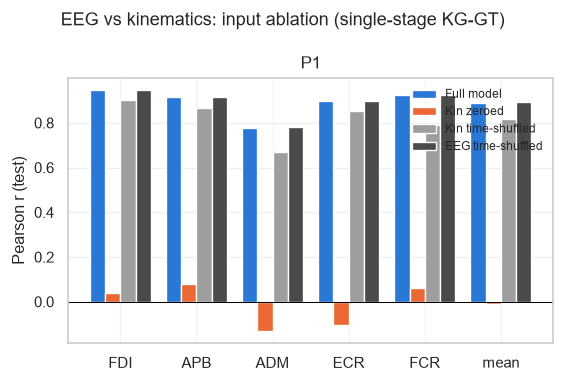

✓  Saved results/input_ablation_1stage.png and results/input_ablation_1stage.csv


In [19]:
# ============================================================================
# HOW MUCH DOES THE MODEL USE EEG vs KINEMATICS?  (test set, input ablation)
# ============================================================================
# For each subject the best model is run on the TEST loader through the same
# prepare_batch (normalisation + kin column drop) as the evaluation above; the
# normalised inputs are then perturbed:
#   full         unchanged
#   kin_zero     kinematics = 0 in z-space (= per-feature training mean)
#   kin_shuffle  kinematics time-shuffled within each window (fixed, seeded permutation)
#   eeg_shuffle  EEG time-shuffled within each window (fixed, seeded permutation)
# Reported: Pearson r per muscle + mean, and the mean predicted level during
# rest (test target below the per-muscle 10th percentile of the TRAINING target;
# the notebook has no absolute rest threshold — the loss uses a per-window
# relative one), full vs kin-zeroed.  All values in normalised (z) units.
# ─────────────────────────────────────────────────────────────────────────────
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from main import (
    input_ablation, rest_threshold_from_loader,
    ABLATION_CONDITIONS, ABLATION_LABELS, ABLATION_COLORS,
)

EMG_NAMES       = ["FDI", "APB", "ADM", "ECR", "FCR"]
REST_PERCENTILE = 10.0
ABLATION_SEED   = CONFIG["training"]["seed"]

ablation_results = {}
_abl_rows = []
for _subj, _res in per_subject_results.items():
    _cfg = _res["cfg"]
    _pb  = _res["prepare_batch"]
    _bm  = _res["model"]          # best.pt already loaded by the training loop
    _bm.eval()

    # rest threshold from the training targets (unshuffled, no dropped windows)
    _train_eval_loader = DataLoader(_res["train_ds"], batch_size=_cfg["training"]["batch_size"],
                                    shuffle=False, num_workers=0)
    _rest_thr = rest_threshold_from_loader(_train_eval_loader, _pb, q=REST_PERCENTILE)

    _abl = input_ablation(
        _bm, _res["test_loader"], _pb, device,
        seed=ABLATION_SEED,
        use_amp=_cfg["training"].get("use_amp", False),
        rest_threshold=_rest_thr,
    )
    _abl.predictions.clear()      # keep only the summaries in memory
    ablation_results[_subj] = _abl

    print(f"\n{'─'*60}\n  {_subj}\n{'─'*60}")
    print(_abl.as_table(EMG_NAMES))
    _rf = _abl.r_mean["full"]
    print(f"  Δr (full − kin_zero)    = {_rf - _abl.r_mean['kin_zero']:+.3f}")
    print(f"  Δr (full − kin_shuffle) = {_rf - _abl.r_mean['kin_shuffle']:+.3f}")
    print(f"  Δr (full − eeg_shuffle) = {_rf - _abl.r_mean['eeg_shuffle']:+.3f}")
    _abl_rows.append({
        "Subject": _subj,
        **{f"r_{c}": _abl.r_mean[c] for c in ABLATION_CONDITIONS},
        "rest_target": float(np.nanmean(_abl.rest_target)),
        "rest_pred_full": float(np.nanmean(_abl.rest_pred["full"])),
        "rest_pred_kin_zero": float(np.nanmean(_abl.rest_pred["kin_zero"])),
    })

ablation_df = pd.DataFrame(_abl_rows)
if len(ablation_df) > 1:
    _gm = ablation_df.drop(columns="Subject").mean().to_dict()
    _gm["Subject"] = "GRAND MEAN"
    ablation_df = pd.concat([ablation_df, pd.DataFrame([_gm])], ignore_index=True)
print("\n" + "=" * 65)
print("  INPUT ABLATION SUMMARY (mean Pearson r over muscles; rest level in z units)")
print("=" * 65)
print(ablation_df.round(3).to_string(index=False))

# ── Bar plot: r per muscle, one bar per condition, one panel per subject ────
_n = len(ablation_results)
_ncols = min(3, _n)
_nrows = int(np.ceil(_n / _ncols))
fig_abl, _axes = plt.subplots(_nrows, _ncols, figsize=(4.8 * _ncols, 3.2 * _nrows),
                              squeeze=False, sharey=True, facecolor="white")
_x = np.arange(len(EMG_NAMES) + 1)
_w = 0.8 / len(ABLATION_CONDITIONS)
for _ax, (_subj, _abl) in zip(_axes.flat, ablation_results.items()):
    for _k, _c in enumerate(ABLATION_CONDITIONS):
        _vals = list(_abl.r[_c]) + [_abl.r_mean[_c]]
        _ax.bar(_x + (_k - (len(ABLATION_CONDITIONS) - 1) / 2) * _w, _vals, _w,
                color=ABLATION_COLORS[_c], label=ABLATION_LABELS[_c])
    _ax.axhline(0, color="black", linewidth=0.6)
    _ax.set_xticks(_x)
    _ax.set_xticklabels(EMG_NAMES + ["mean"])
    _ax.set_title(_subj, fontsize=10)
    _ax.grid(axis="y", alpha=0.3)
for _ax in list(_axes.flat)[_n:]:
    _ax.axis("off")
_axes[0, 0].set_ylabel("Pearson r (test)")
_axes[0, 0].legend(fontsize=7, frameon=False)
fig_abl.suptitle("EEG vs kinematics: input ablation (single-stage KG-GT)", fontsize=11)
fig_abl.tight_layout()
os.makedirs("results", exist_ok=True)
fig_abl.savefig("results/input_ablation_1stage.png", dpi=200, bbox_inches="tight")
ablation_df.to_csv("results/input_ablation_1stage.csv", index=False)
plt.show()
print("✓  Saved results/input_ablation_1stage.png and results/input_ablation_1stage.csv")


In [20]:
# ─────────────────────────────────────────────────────────────────────────────
# INTERPRETABILITY — Full-Signal Triptych (All Subjects × All 10-s Windows)
# ─────────────────────────────────────────────────────────────────────────────
# For each subject in per_subject_results:
#   • Loads best model (already loaded from disk during training loop)
#   • Iterates over EVERY test series in test_ds._windows
#   • Slices non-overlapping 10-second windows from start to end
#   • Generates one plot_interpretability_triptych per window
#   • Saves to: outputs/interpretability_1stage/{subject}/series{i}_window{w}_{t}s-{t+10}s.png
#
# Scientific rationale for "all series" strategy:
#   Using all test series gives COMPLETE coverage of the held-out signal,
#   rather than cherry-picking a single series.  This reveals how model
#   attention and kinematic edge bias evolve across different task epochs
#   (grasp types, force levels, etc.) without selection bias.
# ─────────────────────────────────────────────────────────────────────────────
import os
import torch
import numpy as np
import matplotlib
matplotlib.use("Agg")   # non-interactive backend → safe for batch saving
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from main.plots import plot_interpretability_triptych

from main.preprocessing_emg_kin import kin_feature_names

# Names of the kinematic model inputs, derived from CONFIG
# (hand pose 10 + gated F_L, F_G + pose velocity 10 + gated-force velocity 2 = 24 features;
#  the GAT edge bias sees the first 12, the kin skip highway the gated forces + all velocities).
_kin_cfg = CONFIG["preprocessing"]["kinematics"]
KIN_FEATURE_NAMES = kin_feature_names(
    _kin_cfg["include_velocity"], _kin_cfg["include_acceleration"], _kin_cfg["drop_indices"],
    gated_force=_kin_cfg.get("gated_force"),
)

EMG_NAMES = ["FDI", "APB", "ADM", "ECR", "FCR"]   # adjust if needed

# ── USER CONFIG ───────────────────────────────────────────────────────────────
window_sec      = 10.0          # duration of each triptych window (seconds)          # duration of each triptych window (seconds)
ATTN_TEMP       = 4.0           # attention softmax temperature (>1 = smoother)
ATTN_SIGMA      = 3.0           # Gaussian smoothing sigma for EEG attention
subjects_to_plot = list(per_subject_results.keys())  # plot all; restrict if needed
# ─────────────────────────────────────────────────────────────────────────────

for _subj in subjects_to_plot:
    _res         = per_subject_results[_subj]
    _bm          = _res["model"];  _bm.eval()
    _test_ds     = _res["test_ds"]
    _pb          = _res["prepare_batch"]
    _emg_mean_t  = _res["emg_mean"]
    _emg_std_t   = _res["emg_std"]
    _cfg         = _res["cfg"]

    _fs     = _cfg["data"].get("fs_eeg", 500.0)
    _win_len = int(window_sec * _fs)

    # Inject attention temperature for smoother heatmaps
    for _layer in _bm.encoder.layers:
        _layer.mhsa.attention_temperature = ATTN_TEMP

    _save_dir = os.path.join("outputs", "interpretability_1stage", _subj)
    os.makedirs(_save_dir, exist_ok=True)

    _emg_mean_np = _emg_mean_t.cpu().numpy()
    _emg_std_np  = _emg_std_t.cpu().numpy()

    print(f"\n{'─'*65}")
    print(f"  {_subj} — {len(_test_ds._windows)} test series")

    _total_plots = 0

    # Extract unique full series (since _test_ds._windows contains hundreds of overlapping windows)
    _unique_series = []
    _seen_ids = set()
    for _e, _k, _m, _start in _test_ds._windows:
        if id(_e) not in _seen_ids:
            _unique_series.append((_e, _k, _m))
            _seen_ids.add(id(_e))


    for _series_idx, (_eeg_full, _kin_full, _emg_full) in enumerate(_unique_series):
        _block_start = 0
        # unique series appear in the dataset's sorted stratified test order
        _real_series = get_split_series("test", int(_subj.lstrip("P")), _test_ds.data_dir)[_series_idx]
        # Number of complete windows that fit inside this series
        _available = _eeg_full.shape[0] - _block_start
        _n_windows = _available // _win_len

        if _n_windows == 0:
            print(f"  Series {_real_series}: too short for one {window_sec:.0f}s window, skipping.")
            continue

        print(f"  Series {_real_series}: {_available} samples → {_n_windows} windows of {window_sec:.0f}s")

        for _w in range(_n_windows):
            _start_idx = _block_start + _w * _win_len
            _end_idx   = _start_idx  + _win_len

            _raw_eeg = torch.tensor(_eeg_full[_start_idx:_end_idx])
            _raw_kin = torch.tensor(_kin_full[_start_idx:_end_idx])
            _raw_emg = torch.tensor(_emg_full[_start_idx:_end_idx])

            _model_inputs, _emg_norm = _pb(
                _raw_eeg.unsqueeze(0),
                _raw_kin.unsqueeze(0),
                _raw_emg.unsqueeze(0),
            )
            _eeg_b = _model_inputs["eeg"]
            _kin_b = _model_inputs["kin"]

            torch.cuda.empty_cache()
            with torch.no_grad():
                with torch.autocast(device_type='cuda', dtype=torch.float16):
                    _pred_b = _bm(_eeg_b, _kin_b)

            _pred_np = _pred_b[0].cpu().float().numpy() * _emg_std_np + _emg_mean_np
            _true_np = _emg_norm[0].cpu().float().numpy() * _emg_std_np + _emg_mean_np

            # EEG temporal attention: average over queries → (H, T)
            _eeg_attn = _bm.encoder.layers[-1].mhsa.last_attn_weights[0].mean(dim=1).cpu().float().numpy()
            _eeg_attn = gaussian_filter1d(_eeg_attn, sigma=ATTN_SIGMA, axis=-1)
            # Free memory immediately
            _bm.encoder.layers[-1].mhsa.last_attn_weights = None

            # Kinematic edge bias
            if hasattr(_bm.gat, "last_kin_edge_bias"):
                _kin_edge = _bm.gat.last_kin_edge_bias[0].cpu().float().numpy()
            else:
                raise RuntimeError("last_kin_edge_bias not found — ensure use_kinematic_guidance=True.")

            _t_start = _w * window_sec
            _t_end   = _t_start + window_sec

            _fig = plot_interpretability_triptych(
                pred=_pred_np,
                target=_true_np,
                eeg_attn=_eeg_attn,
                kin_edge_bias=_kin_edge,
                muscle_names=EMG_NAMES,
                kin_feature_names=KIN_FEATURE_NAMES,
                fs=_fs,
                smooth_hz=5.0,
                cfg=_cfg,
            )
            _fig.suptitle(
                f"{_subj}  |  Series {_real_series}  |  {_t_start:.0f}s – {_t_end:.0f}s",
                fontsize=13, fontweight="bold", y=1.01,
            )

            _fname = os.path.join(
                _save_dir,
                f"series{_real_series:02d}_window{_w:03d}_{_t_start:.0f}s-{_t_end:.0f}s.png",
            )
            _fig.savefig(_fname, dpi=150, bbox_inches="tight")
            plt.close(_fig)
            _total_plots += 1

    print(f"  [{_subj}] Saved {_total_plots} triptych plot(s) → {_save_dir}")

print(f"\n✓  Interpretability triptych generation complete.")
print(f"   Plots saved under: outputs/interpretability_1stage/")


─────────────────────────────────────────────────────────────────
  P1 — 653 test series
  Series 4: 116240 samples → 23 windows of 10s


e:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\main\plots.py:689: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
e:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\main\plots.py:689: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
e:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\main\plots.py:689: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
e:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\main\plots.py:689: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
e:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\main\plo

  Series 5: 210644 samples → 42 windows of 10s


e:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\main\plots.py:689: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
e:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\main\plots.py:689: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
e:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\main\plots.py:689: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
e:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\main\plots.py:689: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()
e:\Research\Interdisciplinary-Schools\Computational-NeuroScience\Team6-2025\main\plo

  [P1] Saved 65 triptych plot(s) → outputs\interpretability_1stage\P1

✓  Interpretability triptych generation complete.
   Plots saved under: outputs/interpretability_1stage/


In [ ]:
# Participant / LOSOCV Setup
# ============================================================================
# Supported values for notebook_cfg["data"]["participant"]:
#   "all"      → LOSOCV over all 12 subjects
#   [1,3,5]    → LOSOCV over a specific list
#   "P2" or 2  → Single-subject training (uses train/val/test series split)
#
# LOSOCV val strategy (Option 2 — scientifically clean):
#   For each fold where p_test is the held-out subject:
#     - val_participant  = last subject in the train list (rotates each fold)
#     - train on remaining N-2 subjects (all their series)
#     - val   on val_participant         (all their series) → early stopping
#     - test  on p_test                  (all their series) → final metric
#   The test subject's data NEVER influences any training decision.
# ─────────────────────────────────────────────────────────────────────────────

participant_spec = notebook_cfg["data"]["participant"]
participant_list = resolve_participants(participant_spec)
is_losocv = isinstance(participant_spec, (list, tuple)) or participant_spec == "all"

if is_losocv:
    print(f"LOSOCV mode: {len(participant_list)} participants -> {participant_list}")
    # Initialise first fold
    p_test = participant_list[0]
    # Use the LAST training subject as val (it rotates each fold naturally)
    _train_candidates = [p for p in participant_list if p != p_test]
    val_participant    = _train_candidates[-1]          # held-out from training for early stopping
    train_participants = _train_candidates[:-1]          # N-2 subjects for actual training
    test_participants  = [p_test]
    split_train = split_val = split_test = "all"
    subject_str = f"LOSO_P{p_test}"
else:
    p_id = participant_list[0]
    train_participants = [p_id]
    val_participant    = p_id          # same subject, different series
    test_participants  = [p_id]
    split_train, split_val, split_test = "train", "val", "test"
    subject_str = f"P{p_id}"

print(f"Active subject string : {subject_str}")
print(f"Train participants    : {train_participants}  ({len(train_participants)} subjects)")
print(f"Val  participant      : [{val_participant}]  (early-stopping signal — clean from test)")
print(f"Test participants     : {test_participants}   (final metric — never seen during training)")
print(f"Dataset splits        : train={split_train!r}  val={split_val!r}  test={split_test!r}")


In [ ]:
# [OPTIONAL] Automatic LOSOCV — Run ALL Folds Unattended
# ============================================================================
# Run this cell to automatically iterate over all LOSOCV folds.
# Only runs when is_losocv = True (participant = "all" or a list).
#
# Val strategy (Option 2 — scientifically clean):
#   val_participant = last element of each fold's train list
#   → early stopping never touches the test subject's data
#
# Training: single stage (train_single_stage) — full KG-GT trained jointly per fold.
# Checkpoints saved to: outputs/checkpoints_1stage/LOSO_P{N}/
# Figures saved to:     outputs/figures/
# Summary CSV saved to: outputs/losocv_results_1stage.csv
#
# Note: Variables from the LAST fold are saved to global scope
# so that downstream individual plotting/evaluation cells can run seamlessly!
# ─────────────────────────────────────────────────────────────────────────────
import copy, gc, time, os
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from torch.utils.data import DataLoader
from main import (
    build_kg_gt_from_config,
    train_model, TrainConfig,
    collect_predictions, compute_metrics, load_checkpoint,
    compute_muscle_edge_prior, build_loss_from_config, channel_weights_from_config,
)
from main.plots import plot_interpretability_triptych, plot_kin_skip_over_time
from main.preprocessing_emg_kin import kin_feature_names

if not is_losocv:
    print("Single-subject mode — skipping auto LOSOCV loop.  Run cells below instead.")
else:
    EMG_NAMES = ["FDI", "APB", "ADM", "ECR", "FCR"]
    cv_rows = []
    os.makedirs("outputs/figures", exist_ok=True)

    for _fold_idx, _p_test in enumerate(participant_list):
        _t_fold = time.time()

        # ── Option 2: round-robin training subject held-out for val ───────────
        _train_candidates = [p for p in participant_list if p != _p_test]
        val_idx    = _fold_idx % len(_train_candidates)
        _val_p     = _train_candidates[val_idx]
        _train_ps  = [p for i, p in enumerate(_train_candidates) if i != val_idx]
        _test_ps   = [_p_test]
        _subj      = f"LOSO_P{_p_test}"

        print(f"\n{'='*65}")
        print(f"  FOLD {_fold_idx+1}/{len(participant_list)}")
        print(f"  Train  : {_train_ps}  ({len(_train_ps)} subjects)")
        print(f"  Val    : [{_val_p}]  (early-stopping only)")
        print(f"  Test   : [{_p_test}]  (final metric — never seen during training)")
        print(f"{'='*65}")

        # ── Datasets ──────────────────────────────────────────────────────────
        _train_ds = build_dataset_split(notebook_cfg, participants=_train_ps, split="all")
        _val_ds   = build_dataset_split(notebook_cfg, participants=[_val_p],  split="all")
        _test_ds  = build_dataset_split(notebook_cfg, participants=_test_ps,  split="all")

        # ── Normalization stats from training fold only ────────────────────────
        def _unique_arrays(ds):
            seen, kins, emgs = set(), [], []
            for ea, ka, ma, _ in ds._windows:
                k = id(ea)
                if k not in seen:
                    seen.add(k); kins.append(ka); emgs.append(ma)
            return kins, emgs

        _tr_kins, _tr_emgs = _unique_arrays(_train_ds)
        _kin_all = np.concatenate(_tr_kins, axis=0)
        _emg_all = np.concatenate(_tr_emgs, axis=0)

        _emg_mean = torch.tensor(_emg_all.mean(0), dtype=torch.float32, device=device)
        _emg_std  = torch.clamp(torch.tensor(_emg_all.std(0),  dtype=torch.float32, device=device), min=1e-6)
        _kin_mean = torch.tensor(_kin_all.mean(0), dtype=torch.float32, device=device)
        _kin_std  = torch.clamp(torch.tensor(_kin_all.std(0),  dtype=torch.float32, device=device), min=1e-6)

        # ── Edge prior + loss ─────────────────────────────────────────────────
        _prior_np   = compute_muscle_edge_prior(_tr_emgs)
        _edge_prior = torch.from_numpy(_prior_np)
        _cw = channel_weights_from_config(   # loss.channel_weights ("auto": from the training fold)
            notebook_cfg["training"], (_emg_all - _emg_mean.cpu().numpy()) / _emg_std.cpu().numpy())
        _loss_fn    = build_loss_from_config(notebook_cfg["training"], channel_weights=_cw)

        # ── prepare_batch ─────────────────────────────────────────────────────
        _drop_idx = notebook_cfg["preprocessing"]["kinematics"]["drop_indices"]
        def _make_pb(em, es, km, ks, dev, drop_idx):
            def _pb(eeg, kin, emg):
                eeg = eeg.to(dev, non_blocking=True)
                kin = kin.to(dev, non_blocking=True)
                emg = emg.to(dev, non_blocking=True)
                kn  = (kin - km) / ks
                if drop_idx:
                    keep = [i for i in range(kn.shape[-1]) if i not in drop_idx]
                    kn   = kn[..., keep]
                return {"eeg": eeg, "kin": kn}, (emg - em) / es
            return _pb
        _pb = _make_pb(_emg_mean, _emg_std, _kin_mean, _kin_std, device, _drop_idx)

        # ── Dims ──────────────────────────────────────────────────────────────
        _s_eeg, _s_kin, _s_emg = _train_ds[0]
        _bi, _ = _pb(_s_eeg.unsqueeze(0), _s_kin.unsqueeze(0), _s_emg.unsqueeze(0))
        _eeg_dim = _s_eeg.shape[-1]
        _kin_dim = _bi["kin"].shape[-1]

        # ── DataLoaders ───────────────────────────────────────────────────────
        _bs = notebook_cfg["training"]["batch_size"]
        _tr_loader  = DataLoader(_train_ds, batch_size=_bs, shuffle=True,  drop_last=True,  pin_memory=True, num_workers=0)
        _val_loader = DataLoader(_val_ds,   batch_size=_bs, shuffle=False, pin_memory=True, num_workers=0)
        _te_loader  = DataLoader(_test_ds,  batch_size=_bs, shuffle=False, pin_memory=True, num_workers=0)

        # ── SINGLE STAGE: full KG-GT trained jointly (same routine as above) ──
        _ss = notebook_cfg["training"]["single_stage"]
        print(f"  Single-stage: full KG-GT joint training ({_ss['epochs']} epochs, lr={_ss['lr']:.0e}) ...")
        _model, _bm, _r, _ckpt_dir = train_single_stage(
            notebook_cfg, _subj, _eeg_dim, _kin_dim, _edge_prior,
            _tr_loader, _val_loader, _pb, _loss_fn, device,
        )

        # ── Evaluation on held-out TEST subject (best.pt already loaded) ─────
        _P, _Y = collect_predictions(
            _bm, _te_loader, _pb, device,
            n_channels=len(EMG_NAMES), use_amp=notebook_cfg["training"]["use_amp"],
        )
        _m = compute_metrics(_P, _Y, channel_names=EMG_NAMES)
        print(f"\n  [P{_p_test} TEST RESULTS]")
        print(_m.as_table())

        cv_rows.append({
            "Fold":         _subj,
            "val_subject":  f"P{_val_p}",
            "train_n":      len(_train_ps),
            **{f"RMSE_{n}":    float(_m.rmse[i])    for i, n in enumerate(EMG_NAMES)},
            **{f"nRMSE_{n}":   float(_m.nrmse[i])   for i, n in enumerate(EMG_NAMES)},
            **{f"MAE_{n}":     float(_m.mae[i])     for i, n in enumerate(EMG_NAMES)},
            **{f"Pearson_{n}": float(_m.pearson[i])  for i, n in enumerate(EMG_NAMES)},
            **{f"CCC_{n}":     float(_m.ccc[i])      for i, n in enumerate(EMG_NAMES)},
            **{f"R2_{n}":      float(_m.r2[i])       for i, n in enumerate(EMG_NAMES)},
            **{f"VAF_{n}":     float(_m.vaf[i])      for i, n in enumerate(EMG_NAMES)},
            "RMSE_mean":    float(_m.rmse.mean()),
            "nRMSE_mean":   float(_m.nrmse.mean()),
            "MAE_mean":     float(_m.mae.mean()),
            "Pearson_mean": float(_m.pearson.mean()),
            "CCC_mean":     float(_m.ccc.mean()),
            "R2_mean":      float(_m.r2.mean()),
            "VAF_mean":     float(_m.vaf.mean()),
        })

        # ── Save Plots for this fold ──────────────────────────────────────────
        # 1. Training History (single stage)
        fig_hist, ax1 = plt.subplots(1, 1, figsize=(8, 4), facecolor="white")
        ss_epochs = np.arange(1, len(_r.history["train"]) + 1)
        ax1.plot(ss_epochs, _r.history["train"], label="Single-stage Train", color="#4C9BE8", linewidth=1.5)
        ax1.plot(ss_epochs, _r.history["val"],   label="Single-stage Val",   color="#E87B4C", linewidth=1.5)
        ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss"); ax1.set_title(f"Single-stage — {_subj}")
        ax1.legend(); ax1.grid(alpha=0.3)

        plt.suptitle(f"Single-stage Training History — {_subj}", fontweight="bold")
        plt.tight_layout()
        plt.savefig(f"outputs/figures/history_1stage_{_subj}.png", dpi=300)
        plt.close(fig_hist)

        # 2. Interpretability Triptych (Continuous Test Window)
        fs = notebook_cfg["data"].get("fs_eeg", 500.0)
        eeg_full, kin_full, emg_full, block_start_idx = _test_ds._windows[0]
        start_idx = block_start_idx + int(0.0 * fs)
        end_idx   = block_start_idx + int(10.0 * fs)

        raw_eeg = torch.tensor(eeg_full[start_idx : end_idx])
        raw_kin = torch.tensor(kin_full[start_idx : end_idx])
        raw_emg = torch.tensor(emg_full[start_idx : end_idx])

        model_inputs, emg_norm = _pb(raw_eeg.unsqueeze(0), raw_kin.unsqueeze(0), raw_emg.unsqueeze(0))
        eeg_b = model_inputs["eeg"]
        kin_b = model_inputs["kin"]
        emg_b = emg_norm

        _bm.eval()
        for layer in _bm.encoder.layers:
            layer.mhsa.attention_temperature = 4.0

        with torch.no_grad():
            pred_b = _bm(eeg_b, kin_b)

        pred_np = pred_b[0].cpu().float().numpy()   
        true_np = emg_b[0].cpu().float().numpy()    

        emg_mean_np = _emg_mean.cpu().numpy()
        emg_std_np  = _emg_std.cpu().numpy()
        pred_np = pred_np * emg_std_np + emg_mean_np
        true_np = true_np * emg_std_np + emg_mean_np

        eeg_attn_np = _bm.encoder.layers[-1].mhsa.last_attn_weights[0].cpu().float().numpy()
        eeg_attn_np = gaussian_filter1d(eeg_attn_np, sigma=3.0, axis=-1)

        if hasattr(_bm.gat, "last_kin_edge_bias"):
            kin_edge_np = _bm.gat.last_kin_edge_bias[0].cpu().float().numpy()
        else:
            kin_edge_np = np.zeros((pred_np.shape[0], 4, len(EMG_NAMES), len(EMG_NAMES)))

        _kcfg = notebook_cfg["preprocessing"]["kinematics"]
        KIN_FEATURE_NAMES = kin_feature_names(   # follows CONFIG (24: pose, gated forces, their velocities)
            _kcfg["include_velocity"], _kcfg["include_acceleration"], _kcfg["drop_indices"],
            gated_force=_kcfg.get("gated_force"),
        )

        fig_triptych = plot_interpretability_triptych(
            pred=pred_np,
            target=true_np,
            eeg_attn=eeg_attn_np,
            kin_edge_bias=kin_edge_np,
            muscle_names=EMG_NAMES,
            kin_feature_names=KIN_FEATURE_NAMES,
            fs=fs,
            smooth_hz=5.0,
            cfg=notebook_cfg,
        )
        plt.savefig(f"outputs/figures/interpretability_1stage_{_subj}.png", dpi=300)
        plt.close(fig_triptych)

        # 3. Kinematic Skip Highway Diagnostic Plot
        fig_skip = plot_kin_skip_over_time(
            model=_bm,
            eeg_window=eeg_b,
            kin_window=kin_b,
            emg_target=true_np,
            emg_mean=_emg_mean,
            emg_std=_emg_std,
            smooth_hz=5.0,
            emg_names=EMG_NAMES,
            fs=fs,
            cfg=notebook_cfg,
        )
        plt.savefig(f"outputs/figures/kin_skip_1stage_{_subj}.png", dpi=300)
        plt.close(fig_skip)

        # Save last fold variables to global scope for downstream single-subject cells
        if _fold_idx == len(participant_list) - 1:
            stage1_model = None
            model = _model
            best_model = _bm
            train_loader = _tr_loader
            val_loader = _val_loader
            test_loader = _te_loader
            train_ds = _train_ds
            val_ds = _val_ds
            test_ds = _test_ds
            prepare_batch = _pb
            emg_mean = _emg_mean
            emg_std = _emg_std
            kin_mean = _kin_mean
            kin_std = _kin_std
            result_single = _r
            result_stage1 = _r
            result_stage2 = _r
            subject_str = _subj
            edge_prior = _edge_prior
            true_eeg_dim = _eeg_dim
            true_kin_dim = _kin_dim
            print("\n[!] Saved last fold variables to global scope for downstream analysis cells.")
        else:
            del _model, _bm, _train_ds, _val_ds, _test_ds
            del _tr_loader, _val_loader, _te_loader
            torch.cuda.empty_cache(); gc.collect()

        print(f"  Fold {_fold_idx+1} done in {(time.time()-_t_fold)/60:.1f} min")

    # ── Cross-Validation Summary ──────────────────────────────────────────────
    cv_df = pd.DataFrame(cv_rows)
    _num_cols = cv_df.select_dtypes("number").columns
    mean_row  = cv_df[_num_cols].mean().to_dict()
    mean_row["Fold"] = "CV MEAN"; mean_row["val_subject"] = "—"
    cv_df = pd.concat([cv_df, pd.DataFrame([mean_row])], ignore_index=True)

    print("\n" + "="*65)
    print("  LEAVE-ONE-SUBJECT-OUT CROSS-VALIDATION SUMMARY")
    print("  Val strategy: Option 2 (training-subject held out for early stopping)")
    print("="*65)
    summary_cols = ["Fold","val_subject","train_n","RMSE_mean","nRMSE_mean","Pearson_mean","CCC_mean","VAF_mean"]
    print(cv_df[summary_cols].to_string(index=False))
    print("="*65)

    os.makedirs("outputs", exist_ok=True)
    cv_df.to_csv("outputs/losocv_results_1stage.csv", index=False)
    print("Full results exported to: outputs/losocv_results_1stage.csv")
    print("DataFrame available as: cv_df")

In [ ]:
# ============================================================================
# [LOSOCV ONLY] Advance to the next fold
# ============================================================================
# When running LOSOCV, run this cell to advance to the next held-out subject,
# then re-run cells B through Q to train & evaluate that fold.
# ─────────────────────────────────────────────────────────────────────────────
if is_losocv:
    # Find current fold index and advance
    _current_idx = participant_list.index(p_test)
    _next_idx = _current_idx + 1
    if _next_idx < len(participant_list):
        p_test = participant_list[_next_idx]
        train_participants = [p for p in participant_list if p != p_test]
        test_participants  = [p_test]
        subject_str = f"LOSO_P{p_test}"
        print(f"Advanced to fold {_next_idx + 1}/{len(participant_list)}: Test = P{p_test}")
        print(f"  Train participants : {train_participants}")
    else:
        print("All LOSOCV folds completed!")
else:
    print("Not in LOSOCV mode — this cell is a no-op.")


In [ ]:
# ── DIAGNOSTIC: Residual Decomposition (GAT vs Kinematic Skip) ────────────
from main.plots import plot_residual_decomposition

if "KIN_FEATURE_NAMES" in globals():   # defined in the interpretability cell
    print("GAT edge-bias inputs :", best_model.gat_kin_feature_names(KIN_FEATURE_NAMES))
    print("Kin skip inputs      :", best_model.skip_kin_feature_names(KIN_FEATURE_NAMES))

fig = plot_residual_decomposition(
    model      = best_model,
    eeg_window = eeg_b,          # Tensor (1, T, 32)
    kin_window = kin_b,          # Tensor (1, T, 24) — hand pose, gated forces and their velocities
    emg_target = true_np,        # np.ndarray (T, 5) — physical scale
    emg_mean   = emg_mean,       # ← NEW: un-normalizes model outputs to physical scale
    emg_std    = emg_std,        # ← NEW
    smooth_hz  = 5.0,           # optional low-pass Hz (set None to disable smoothing)
    emg_names  = EMG_NAMES,
    fs         = fs,
    cfg        = CONFIG,
)
plt.show()


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# STATIC EDGE BIAS + MUSCLE SYNERGY MATRIX + KINEMATIC WEIGHT HEATMAP
# ─────────────────────────────────────────────────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from main import plot_muscle_synergy_matrix, plot_kin_edge_linear_weights

# ── 1. Biological prior vs. learned static edge bias ──────────────────────
gat = best_model.gat
learned_bias = gat.edge_bias.detach().cpu().numpy()    # (H, N, N)
prior_anchor  = gat.edge_prior_anchor.cpu().numpy()    # (H, N, N)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), facecolor="white")
kw = dict(
    annot=True, fmt=".3f", cmap="mako",
    xticklabels=EMG_NAMES, yticklabels=EMG_NAMES,
    cbar_kws={"shrink": 0.85}, linewidths=0.8, linecolor="white",
)
sns.heatmap(prior_anchor.mean(0), ax=axes[0], **kw)
axes[0].set_title(
    "Biological Prior  (log-prior, mean over heads)\n"
    "= log(EMG Pearson correlation + eps)", fontsize=11, fontweight="bold"
)
axes[0].set_xlabel("From Muscle"); axes[0].set_ylabel("To Muscle")
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=30, ha="right")

sns.heatmap(learned_bias.mean(0), ax=axes[1], **kw)
axes[1].set_title(
    "Learned Static Edge Bias  (after training, mean over heads)\n"
    "Deviation from prior = knowledge beyond raw correlation",
    fontsize=11, fontweight="bold",
)
axes[1].set_xlabel("From Muscle"); axes[1].set_ylabel("To Muscle")
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=30, ha="right")

plt.suptitle(
    "Edge Bias: Biological Prior  vs.  Learned Muscle Synergy",
    fontsize=13, fontweight="bold",
)
plt.tight_layout()
plt.show()

# ── 2. GAT attention synergy matrix (full test set) ───────────────────────
all_attn = []
best_model.eval()
with torch.no_grad():
    for raw_eeg, raw_kin, raw_emg in test_loader:
        # IMPORTANT: Pass through prepare_batch to drop the force channels (26->20) and normalize!
        model_inputs, _ = prepare_batch(raw_eeg, raw_kin, raw_emg)
        
        # Now pass the properly processed inputs to the model
        best_model(
            model_inputs["eeg"],
            model_inputs["kin"],
        )
        if hasattr(best_model.gat, "last_attn_weights"):
            all_attn.append(best_model.gat.last_attn_weights.cpu().numpy())

if all_attn:
    all_attn_np = np.concatenate(all_attn, axis=0)   # (B*T, H, N, N)
    fig_syn = plot_muscle_synergy_matrix(all_attn_np, EMG_NAMES, cfg=CONFIG)
    plt.show()

# ── DIAGNOSTIC: Predicted vs Actual Inter-Muscle Correlation ──────────────
from main.plots import plot_channel_correlation_matrix

# Collect all predictions and targets from the test loader
all_preds_list, all_targets_list = [], []
best_model.eval()
with torch.no_grad():
    for raw_eeg, raw_kin, raw_emg in test_loader:
        model_inputs, emg_norm = prepare_batch(raw_eeg, raw_kin, raw_emg)
        pred = best_model(model_inputs["eeg"], model_inputs["kin"])
        all_preds_list.append(pred.cpu().float().numpy())
        all_targets_list.append(emg_norm.cpu().float().numpy())

all_preds_flat   = np.concatenate(all_preds_list,   axis=0).reshape(-1, len(EMG_NAMES))
all_targets_flat = np.concatenate(all_targets_list, axis=0).reshape(-1, len(EMG_NAMES))

fig = plot_channel_correlation_matrix(
    y_pred     = all_preds_flat,
    y_true     = all_targets_flat,
    emg_names  = EMG_NAMES,
    cfg        = CONFIG,
)
plt.show()

# ── DIAGNOSTIC: EMG Error Analysis (Bias / Canopy / Temporal Hotspots) ────
from main.plots import plot_emg_error_analysis

fig = plot_emg_error_analysis(
    y_pred    = all_preds_flat,
    y_true    = all_targets_flat,
    emg_names = EMG_NAMES,
    fs        = fs,
    cfg       = CONFIG,
)
plt.show()



# ── 3. Transparent kinematic -> edge weight matrix ────────────────────────
if hasattr(best_model.gat, "kin_edge_linear"):
    W = best_model.gat.kin_edge_linear.weight.detach().cpu().numpy()
    gat_cfg = CONFIG["model"]["gat"]
    fig_kin = plot_kin_edge_linear_weights(
        weight_matrix=W,
        muscle_names=EMG_NAMES,                       
        kin_feature_names=KIN_FEATURE_NAMES[:W.shape[1]],   # GAT edge bias sees the first kin_gat_dim features (pose + gated forces)
        num_heads=gat_cfg["heads"],
        n_nodes=5,
        cfg=CONFIG,
    )
    plt.show()
    print("\nInspect high |weight| columns on d_grip and the finger/wrist positions for key insights.")
else:
    print("kin_edge_linear not found (use_kinematic_guidance may be False).")


In [ ]:
import matplotlib.pyplot as plt
from main import (
    plot_neural_mechanical_latency_lag,
    plot_spectral_power_decomposition,
    plot_kinematic_velocity_acceleration_density,
)

best_model.eval()

# ── PLOT 1: Neural-Mechanical Latency Lag (Time-Shifted Cross-Correlation) ──
print("Generating Plot 1: Neural-Mechanical Latency Lag Analysis...")
fig_lat = plot_neural_mechanical_latency_lag(
    model=best_model,
    eeg_window=eeg_b,               # model_inputs["eeg"], shape: (1, T, 32)
    kin_window=kin_b,               # model_inputs["kin"], shape: (1, T, 24)
    emg_target=true_np,             # un-normalized ground truth array, shape: (T, 5)
    emg_names=EMG_NAMES,
    fs=500,
    max_lag_ms=250,                 # check delays from -250ms to +250ms
    emg_mean=emg_mean,              # un-normalize internal components to match true_np
    emg_std=emg_std,
    cfg=CONFIG
)
plt.show()

# ── PLOT 2: Spectral Power Decomposition (PSD Bandwidth & Canopy Check) ──
print("\nGenerating Plot 2: Spectral Power Decomposition (Welch's PSD)...")
fig_spec = plot_spectral_power_decomposition(
    model=best_model,
    eeg_window=eeg_b,
    kin_window=kin_b,
    emg_target=true_np,
    emg_names=EMG_NAMES,
    fs=500,
    max_freq_hz=20.0,
    emg_mean=emg_mean,
    emg_std=emg_std,
    cfg=CONFIG
)
plt.show()

# ── PLOT 3: Kinematic Velocity & Acceleration Density Alignment ──
print("\nGenerating Plot 3: Kinematic State Separation Density Grid...")
fig_kin_dens = plot_kinematic_velocity_acceleration_density(
    kin_window=kin_b,               # shape: (1, T, 24) or (T, 24); uses the 9 position columns,
                                    # derives velocity/acceleration itself (acc is not a model input)
    emg_target=true_np,
    emg_names=EMG_NAMES,
    fs=500,
    cfg=CONFIG
)
plt.show()
